## **Project Name :**
### **- Finacial Fraud Detection Using Machine Learning**

## **Project Title :**
### **-Empowering Financial Security: Detecting Fraudulent Transactions using Advanced Machine Learning Techniques and Predictive Analytics .**

##### **Step No 1 : Importing Required Libraries** 



In [2]:
# Import Pandas for dataset loading and data manipulation
import pandas as pd 

# Import Numpy for numerical operations 
import numpy as np 

# Import Matplotlib for data visualization 
import matplotlib.pyplot as plt 

# Import Seaborn for statistical data visulization
import seaborn as sns 

# Import Display to show DataFrames in Jupyter Notebook
from IPython.display import display

# Configure Pandas to display all columns 
pd.set_option("display.max_columns", None)

# Configure Pandas to display more rows 
pd.set_option("display.max_rows", 100)

# Set The Visualization Style for Seaborn
sns.set_style(style="whitegrid")

# Create folder to save EDA images
import os
os.makedirs("images", exist_ok=True)

print("Images folder created successfully!")

Images folder created successfully!


##### **Step No 2 : Dataset Loading :**

In [3]:
# Load Dataset 
df = pd.read_csv("DS DATA.csv")

# Clean column names (remove extra spaces )
df.columns = df.columns.str.strip()

# Preview data 
df 

,accountAgeDays,numItems,localTime,paymentMethod,paymentMethodAgeDays,Category,isWeekend,label
0,29,1,4.745402,paypal,28.204861,shopping,0.0,0
1,725,1,4.742303,storecredit,0.000000,electronics,0.0,0
2,845,1,4.921318,creditcard,0.000000,food,1.0,0
3,503,1,4.886641,creditcard,0.000000,electronics,1.0,0
4,2000,1,5.040929,creditcard,0.000000,shopping,0.0,0
...,...,...,...,...,...,...,...,...
39216,986,1,4.836982,creditcard,0.000000,shopping,0.0,0
39217,1647,1,4.876771,creditcard,377.930556,shopping,0.0,0
39218,1591,1,4.742303,creditcard,0.000000,shopping,1.0,0
39219,237,1,4.921318,creditcard,236.082639,shopping,1.0,0


##### **Step No 3 : Data Understanding** 


In [4]:
# Data Understanding and Exploration 

# Check dataset size (rows, columns)
print("Dataset Shape : " , df.shape)

# Get basic info (columns , data types, null values)
print("\nDataset Info : ")
df.info()

#View Statistical Summary of numerical features 
print("\nStatistical Summary : ")
print(df.describe())

 

Dataset Shape :  (39221, 8)

Dataset Info : 
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 39221 entries, 0 to 39220
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   accountAgeDays        39221 non-null  int64  
 1   numItems              39221 non-null  int64  
 2   localTime             39221 non-null  float64
 3   paymentMethod         39221 non-null  object 
 4   paymentMethodAgeDays  39221 non-null  float64
 5   Category              39126 non-null  object 
 6   isWeekend             38661 non-null  float64
 7   label                 39221 non-null  int64  
dtypes: float64(3), int64(3), object(2)
memory usage: 2.4+ MB

Statistical Summary : 
       accountAgeDays      numItems     localTime  paymentMethodAgeDays  \
count    39221.000000  39221.000000  39221.000000          39221.000000   
mean       857.563984      1.084751      4.748232            122.641326   
std        804.788212     

##### **Step No 4 : Data Validation**

In [5]:
#  Expected column Validation 

expected_columns = [
    "accountAgeDays",
    "numItems",
    "localTime",
    "paymentMethod",
    "paymentMethodAgeDays",
    "isWeekend",
    "Category",
    "label"
]

missing_columns = [
    col for col in expected_columns if col not in df.columns
]

print("Missing Columns : " , missing_columns)

if missing_columns:
    raise ValueError(f"Required columns missing : {missing_columns}")

# Missing Value Validation 
print("\nMissing Value Count : ")
display(df.isnull().sum().to_frame(name = "Missing Values Count"))

# Duplicate Row Validation 
print("\nDUPLICATE RECORDS")
duplicate_count = df.duplicated().sum()
print("Total Duplicate Rows : " , duplicate_count)

# Unique values validation 
print("\nUNIQUE VALUES")
display(df.nunique())

# Target Variable Validation 
print("\nTARGET VARIABLE VALIDATION")
print("Target Values : " , df["label"].unique())
print("\nTarget Class Distribution : ")
print(df["label"].value_counts(dropna = False))

# Invalid Target Values Check

invalid_target_rows = df[
    df["label"].notna() &
    ~df["label"].isin([0, 1])
]

print("Invalid Target Rows:", len(invalid_target_rows))

# Numerical Values Validation 
numeric_columns = [
    "accountAgeDays",
    "numItems",
    "localTime",
    "paymentMethodAgeDays"
]
print("\nNEGATIVE VALUES")

display(
    (df[numeric_columns] < 0).sum()
    .to_frame(name = "Negative Values Count")
)

# Final Validation Summary

print("\n" + "=" * 50)
print("DATA VALIDATION SUMMARY")
print("=" * 50)

print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])
print("Missing Values:", df.isnull().sum().sum())
print("Duplicate Rows:", duplicate_count)
print("Invalid Target Rows:", len(invalid_target_rows))

Missing Columns :  []

Missing Value Count : 


,Missing Values Count
accountAgeDays,0
numItems,0
localTime,0
paymentMethod,0
paymentMethodAgeDays,0
Category,95
isWeekend,560
label,0



DUPLICATE RECORDS
Total Duplicate Rows :  3033

UNIQUE VALUES


accountAgeDays           1999
numItems                   14
localTime                  25
paymentMethod               3
paymentMethodAgeDays    17094
Category                    3
isWeekend                   2
label                       2
dtype: int64


TARGET VARIABLE VALIDATION
Target Values :  [0 1]

Target Class Distribution : 
label
0    38661
1      560
Name: count, dtype: int64
Invalid Target Rows: 0

NEGATIVE VALUES


,Negative Values Count
accountAgeDays,0
numItems,0
localTime,0
paymentMethodAgeDays,0



DATA VALIDATION SUMMARY
Total Rows: 39221
Total Columns: 8
Missing Values: 655
Duplicate Rows: 3033
Invalid Target Rows: 0


##### **Step No 5 : Data Cleaning**

In [6]:

# Create a separate copy of the original dataset
df_clean = df.copy()



# 1. CHECK DATA BEFORE CLEANING


print("=" * 60)
print("BEFORE DATA CLEANING")
print("=" * 60)

print("Dataset Shape:", df_clean.shape)

print("\nMissing Values:")

display(df_clean.isnull().sum())

print("\nDuplicate Rows:")

print(df_clean.duplicated().sum())


# 2. STANDARDIZE CATEGORICAL TEXT

# Remove unnecessary spaces from paymentMethod
df_clean["paymentMethod"] = (
    df_clean["paymentMethod"]
    .astype("string")
    .str.strip()
    .str.lower()
)

# Remove unnecessary spaces from Category
df_clean["Category"] = (
    df_clean["Category"]
    .astype("string")
    .str.strip()
    .str.lower()
)

# Standardizing text avoids duplicate category names
# caused by uppercase/lowercase or extra spaces

# 3. HANDLE MISSING CATEGORY VALUES

# Replace missing Category values with Unknown
df_clean["Category"] = (
    df_clean["Category"]
    .fillna("unknown")
)

# Keep missing isWeekend values unchanged
# because their relationship with the target requires investigation

# 4. CHECK INVALID NUMERICAL VALUES

# Check negative account age
invalid_account_age = df_clean[
    df_clean["accountAgeDays"] < 0
]

# Check invalid number of items
invalid_num_items = df_clean[
    df_clean["numItems"] <= 0
]

# Check negative payment method age
invalid_payment_age = df_clean[
    df_clean["paymentMethodAgeDays"] < 0
]

print("\nINVALID DATA CHECK")

print(
    "Negative Account Age:",
    len(invalid_account_age)
)

print(
    "Zero or Negative Items:",
    len(invalid_num_items)
)

print(
    "Negative Payment Method Age:",
    len(invalid_payment_age)
)

# 5. CHECK INVALID TARGET VALUES

invalid_target = df_clean[
    ~df_clean["label"].isin([0, 1])
]

print(
    "\nInvalid Target Records:",
    len(invalid_target)
)

# 6. DUPLICATE RECORD AUDIT

# Count duplicate rows without deleting them
duplicate_count_after = df_clean.duplicated().sum()

print(
    "\nDuplicate Rows Retained for Investigation:",
    duplicate_count_after
)

# We are not dropping duplicates because:
# The dataset does not provide a transaction ID.
# Repeated feature combinations may not always be duplicate transactions.

# 7. CHECK MISSING VALUES AFTER CLEANING

print("\nMISSING VALUES AFTER CLEANING")

display(df_clean.isnull().sum())


# PHASE 8: isWeekend MISSING VALUE ANALYSIS
# Check existing values
print("isWeekend Value Distribution:")

print(
    df_clean["isWeekend"].value_counts(dropna=False)
)

# Calculate missing percentage
missing_percentage = (
    df_clean["isWeekend"].isnull().mean() * 100
)

print("\nMissing Percentage:", round(missing_percentage, 2), "%")

# Check missing records
missing_weekend = df_clean[
    df_clean["isWeekend"].isnull()
]

print("\nMissing Weekend Records:", len(missing_weekend))

print("\nINITIAL DATA CLEANING COMPLETED!")

BEFORE DATA CLEANING
Dataset Shape: (39221, 8)

Missing Values:


accountAgeDays            0
numItems                  0
localTime                 0
paymentMethod             0
paymentMethodAgeDays      0
Category                 95
isWeekend               560
label                     0
dtype: int64


Duplicate Rows:
3033

INVALID DATA CHECK
Negative Account Age: 0
Zero or Negative Items: 0
Negative Payment Method Age: 0

Invalid Target Records: 0

Duplicate Rows Retained for Investigation: 3033

MISSING VALUES AFTER CLEANING


accountAgeDays            0
numItems                  0
localTime                 0
paymentMethod             0
paymentMethodAgeDays      0
Category                  0
isWeekend               560
label                     0
dtype: int64

isWeekend Value Distribution:
isWeekend
0.0    19348
1.0    19313
NaN      560
Name: count, dtype: int64

Missing Percentage: 1.43 %

Missing Weekend Records: 560

INITIAL DATA CLEANING COMPLETED!


In [7]:
 # MISSING isWeekend VS TARGET ANALYSIS

print("MISSING isWeekend VS TARGET")

display(
    pd.crosstab(
        df_clean["isWeekend"].isnull(),
        df_clean["label"],
        margins=True
    )
)

print("\nMISSING VALUE PERCENTAGE")

display(
    (df_clean.isnull().mean() * 100)
    .round(2)
    .to_frame(name="Missing Percentage")
)

MISSING isWeekend VS TARGET


label,0,1,All
isWeekend,,,
False,38661,0,38661
True,0,560,560
All,38661,560,39221



MISSING VALUE PERCENTAGE


,Missing Percentage
accountAgeDays,0.00
numItems,0.00
localTime,0.00
paymentMethod,0.00
paymentMethodAgeDays,0.00
Category,0.00
isWeekend,1.43
label,0.00


#### **Step No 6 : Exploratory Data Analysis (EDA)**

##### **1) UNIVARIATE ANALYSIS**

In [8]:
# 1.Numerical and Categorical Data Type Verification
import matplotlib.pyplot as plt
import seaborn as sns

# Define Numerical Features
numerical_features = [
    "accountAgeDays",
    "numItems",
    "localTime",
    "paymentMethodAgeDays"
]

# 2. Define Categorical Features
categorical_features = [
    "paymentMethod",
    "Category"
]

# Check Feature Data Types
print("NUMERICAL FEATURES DATA TYPES")

display(df_clean[numerical_features].dtypes)

print("\nCATEGORICAL FEATURES DATA TYPES")

display(df_clean[categorical_features].dtypes)

NUMERICAL FEATURES DATA TYPES


accountAgeDays            int64
numItems                  int64
localTime               float64
paymentMethodAgeDays    float64
dtype: object


CATEGORICAL FEATURES DATA TYPES


paymentMethod    string[python]
Category         string[python]
dtype: object

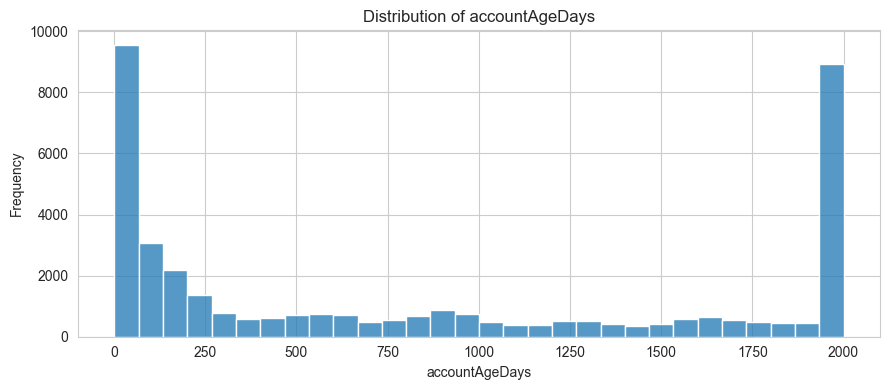

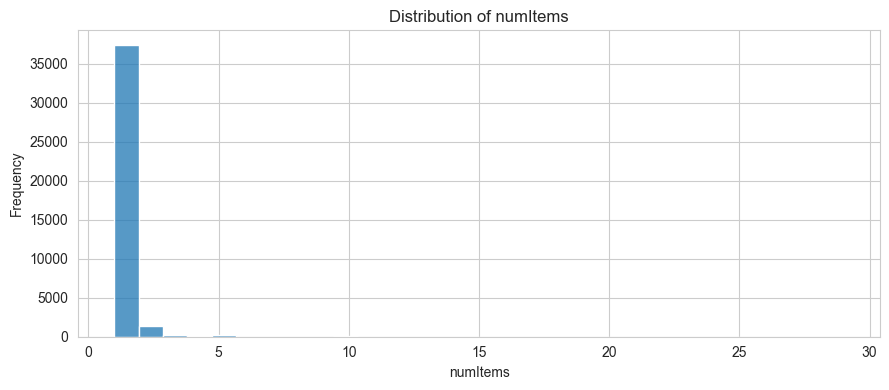

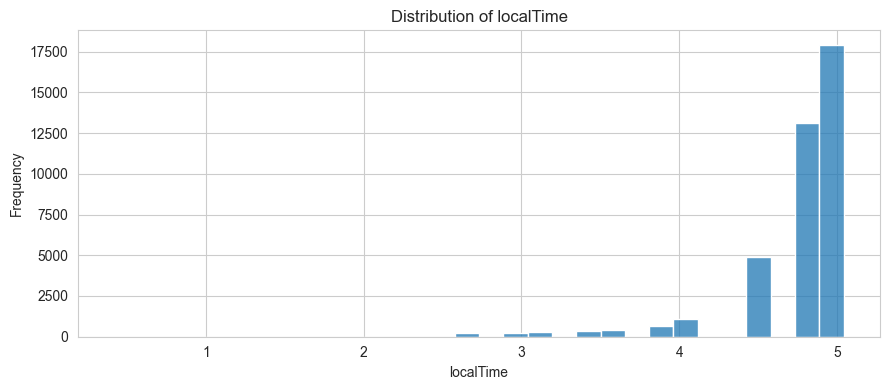

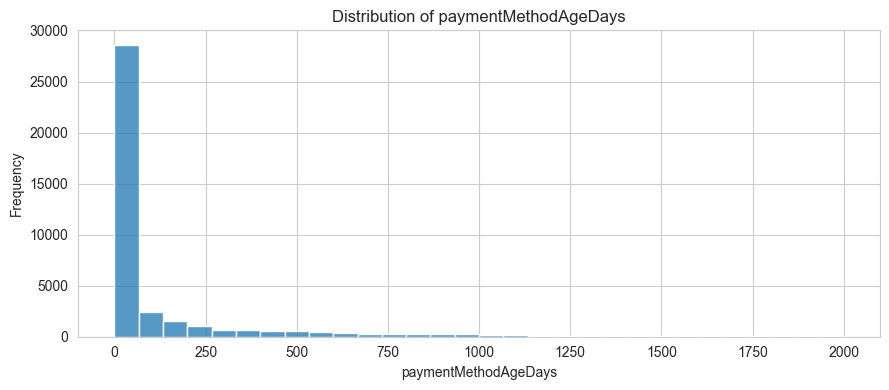

In [9]:
# 3. NUMERICAL FEATURE DISTRIBUTION

for column in numerical_features:
    # Create a histogram for each numerical feature 
    plt.figure(figsize = (9,4))
    #Plot histogram to understand distribution 
    sns.histplot(
        data = df_clean,
        x = column,
        bins = 30,
    )
    # Add chart title 
    plt.title(f"Distribution of {column}")
    # Add x-axis label 
    plt.xlabel(column)
    # Add y-axis label
    plt.ylabel("Frequency")
    # Display the plot
    plt.tight_layout()
    plt.savefig(
    f"images/{column}_distribution.png",
    dpi=300,
    bbox_inches="tight"
)
    plt.show()

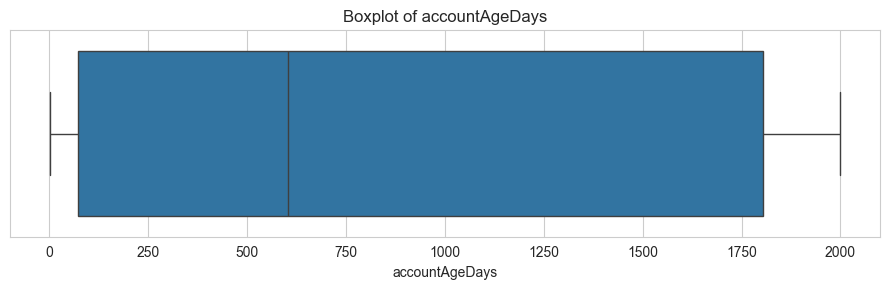

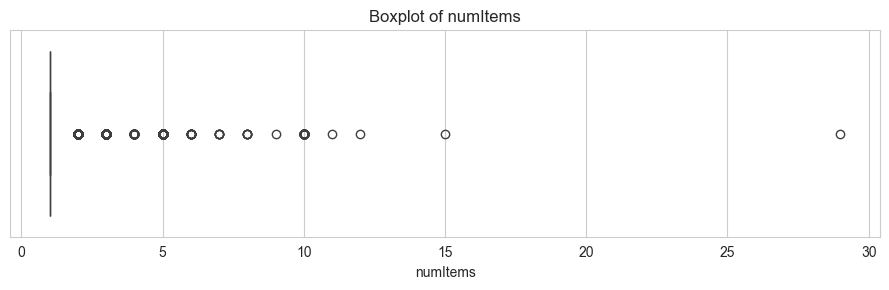

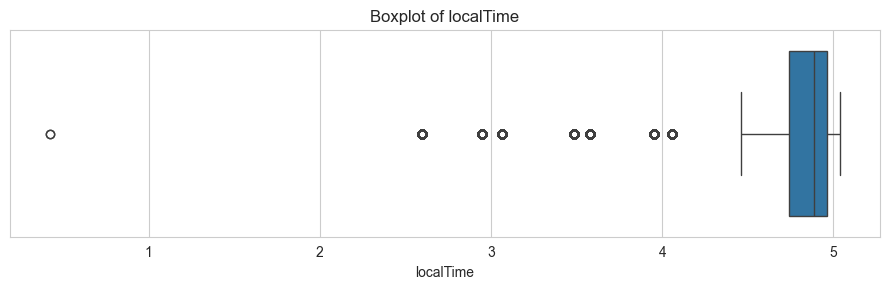

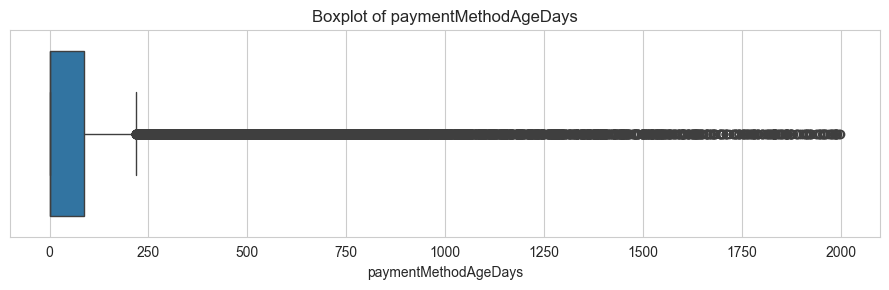

In [10]:
# 4. BOX PLOT NUMERICAL FEATURES 

for column in numerical_features:
    #Create a figure
    plt.figure(figsize = (9,3))
    # Plot boxplot to understand spread and possible outliers
    sns.boxplot(
        data = df_clean,
        x = column
    )
    
    # Add title 
    plt.title(f"Boxplot of {column}")
    
    # Display the plot 
    plt.tight_layout()
    plt.savefig(
    f"images/{column}_boxplot.png",
    dpi=300,
    bbox_inches="tight"
)
    plt.show()

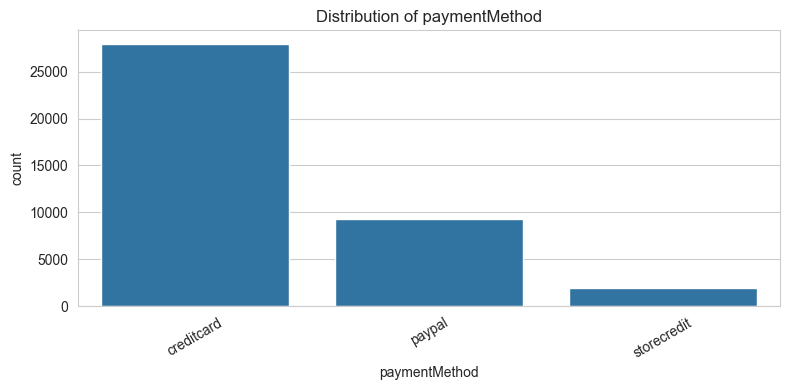

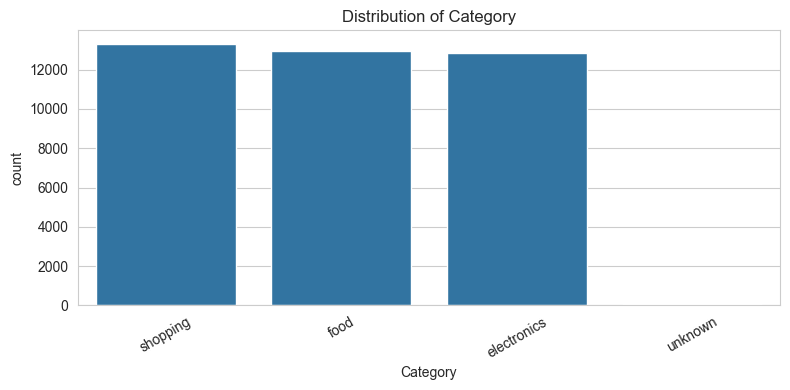

In [11]:
# 5. CATEGORICAL FEATURE DISTRIBUTION

for column in categorical_features:
    #Create a figure
    plt.figure(figsize = (8,4))
    # Plot category counts 
    sns.countplot(
        data = df_clean,
        x = column,
        order = df_clean[column].value_counts().index
    )
    # Add Chart title 
    plt.title(f"Distribution of {column}")
    # Rotate labels for readability
    plt.xticks(rotation = 30)
    # Display the plot
    plt.tight_layout()
    plt.savefig(
    f"images/{column}_categorical.png",
    dpi=300,
    bbox_inches="tight"
)
    plt.show()

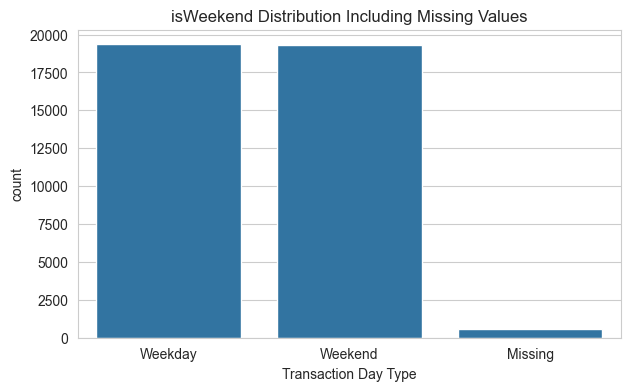

In [12]:
# 6. WEEKEND FEATURE DISTRIBUTION

# Create a temporary column for visualization only
weekend_visual = df_clean["isWeekend"].map({
    0: "Weekday",
    1: "Weekend"
}).fillna("Missing")

# Plot the weekend distribution including missing values 
plt.figure(figsize = (7,4))

sns.countplot(x = weekend_visual,
              order = ["Weekday", "Weekend", "Missing"])
plt.title("isWeekend Distribution Including Missing Values")
plt.xlabel("Transaction Day Type")
plt.savefig("images/isWeekend Distribution.png")
plt.show()

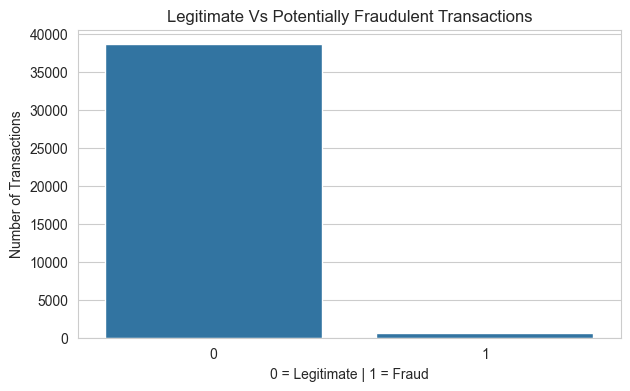

In [13]:
# 7. TARGET VARIABLE DISTRIBUTION

plt.figure(figsize = (7,4))
sns.countplot(
    data = df_clean,
    x = "label"
)
plt.title("Legitimate Vs Potentially Fraudulent Transactions")
plt.xlabel("0 = Legitimate | 1 = Fraud")
plt.ylabel("Number of Transactions")
plt.savefig("images/Target Variable Distribution.png")
plt.show()

In [14]:
# 8. Numerical Summary 
print("\nNUMERICAL FEATURE SUMMARY")
display(
    df_clean[numerical_features].describe().T
)


NUMERICAL FEATURE SUMMARY


,count,mean,std,min,25%,50%,75%,max
accountAgeDays,39221.0,857.563984,804.788212,1.000000,72.000000,603.000000,1804.000000,2000.000000
numItems,39221.0,1.084751,0.566899,1.000000,1.000000,1.000000,1.000000,29.000000
localTime,39221.0,4.748232,0.389360,0.421214,4.742303,4.886641,4.962055,5.040929
paymentMethodAgeDays,39221.0,122.641326,283.569177,0.000000,0.000000,0.012500,87.510417,1999.580556


In [15]:
# 9. CATEGORICAL SUMMARY 
print("\nCATEGORICAL FEATURE SUMMARY")

for column in categorical_features:
    print(f"\n{column} value counts:")
    
    display(
        df_clean[column].value_counts(dropna = False)
    )
print("\nUNIVARIATE ANALYSIS COMPLETED!")


CATEGORICAL FEATURE SUMMARY

paymentMethod value counts:


paymentMethod
creditcard     28004
paypal          9303
storecredit     1914
Name: count, dtype: Int64


Category value counts:


Category
shopping       13328
food           12964
electronics    12834
unknown           95
Name: count, dtype: Int64


UNIVARIATE ANALYSIS COMPLETED!


##### **2) BIVARIATE ANALYSIS**

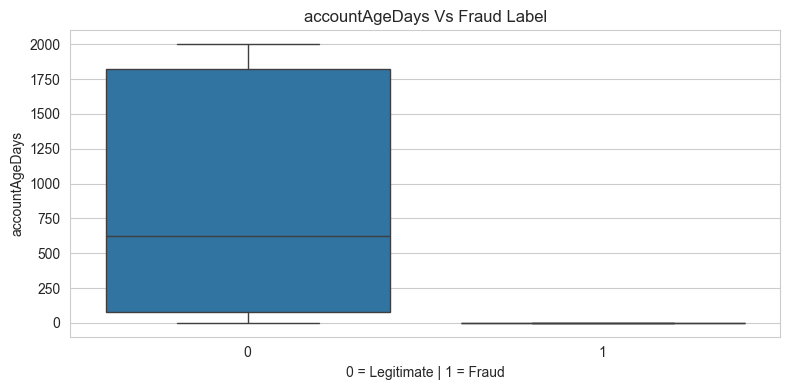

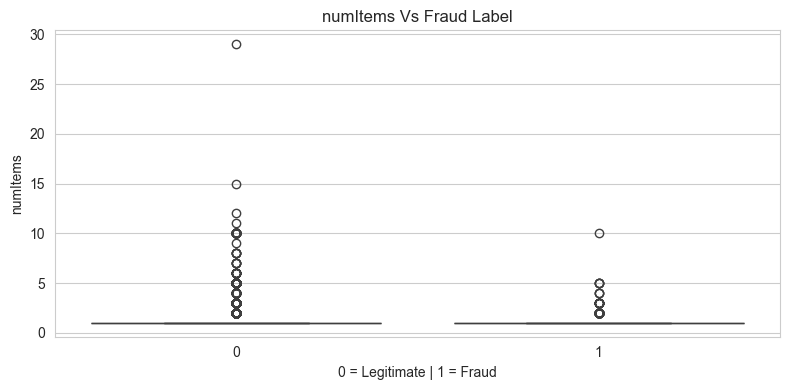

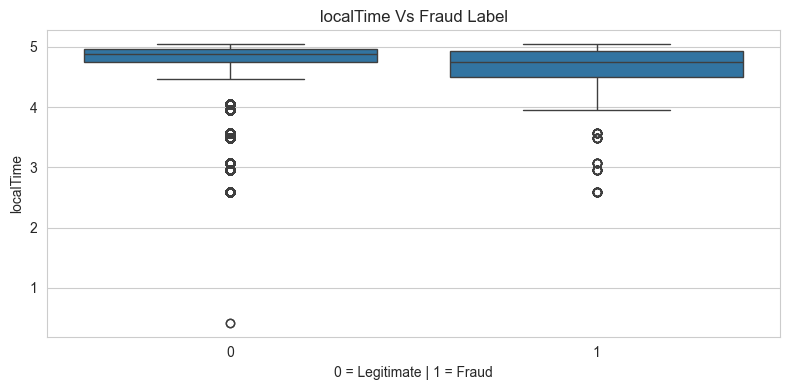

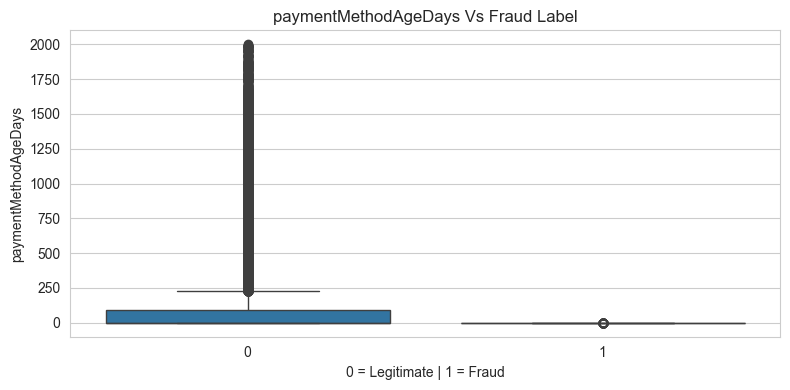

In [16]:
  # 1. NUMERICAL FEATURE VS TARGET

for column in numerical_features:

    # Create a figure
    plt.figure(figsize=(8, 4))

    # Compare numerical feature distribution by fraud label
    sns.boxplot(
        data=df_clean,
        x="label",
        y=column
    )

    # Add Title
    plt.title(f"{column} Vs Fraud Label")

    # Add axis labels
    plt.xlabel("0 = Legitimate | 1 = Fraud")
    plt.ylabel(column)

    # Save the plot
    plt.tight_layout()
    plt.savefig(
        f"images/{column}_vs_target.png",
        dpi=300,
        bbox_inches="tight"
    )

    # Display the plot
    plt.show()


paymentMethod Vs label Percentage


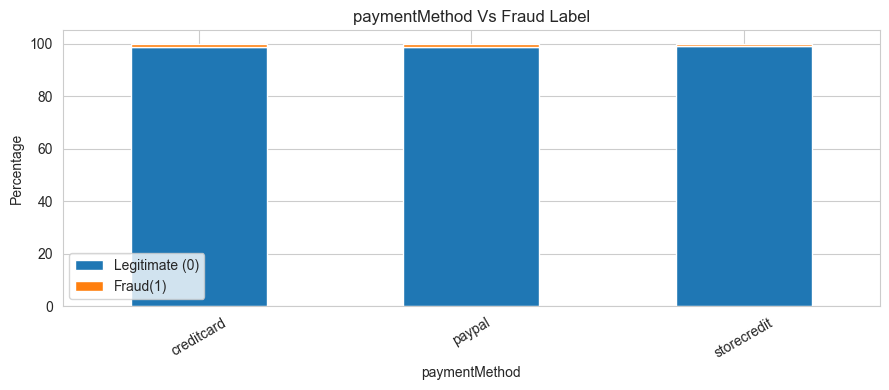


Category Vs label Percentage


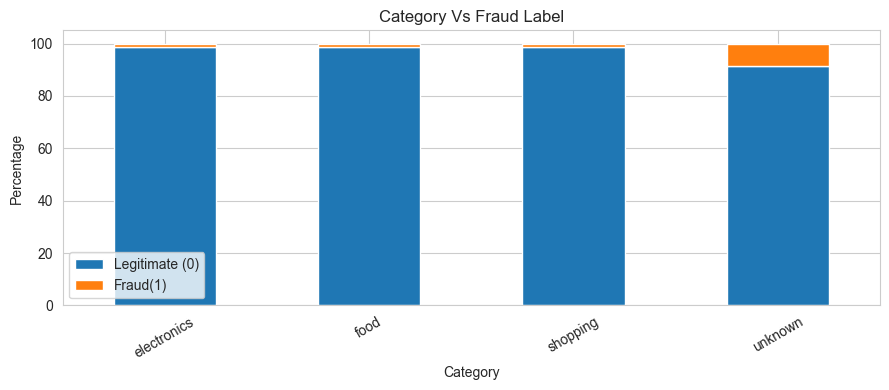

In [17]:
# 2. CATEGORICAL FEATURE VS TARGET 
for column in categorical_features:
    # Calculate percentage distribution by target class 
    fraud_distribution = pd.crosstab(
        df_clean[column],
        df_clean["label"],
        normalize = "index"
    ) * 100
    
    # Display the calculated percentage 
    print(f"\n{column} Vs label Percentage")
    
    # Plot the relationship 
    fraud_distribution.plot(
        kind = "bar",
        stacked = True,
        figsize = (9,4)
    )
    # Add chart title 
    plt.title(f"{column} Vs Fraud Label")
    
    # Add Axis Labels
    plt.xlabel(column)
    plt.ylabel("Percentage")
    
    # Display legend 
    plt.legend(
        ["Legitimate (0)", "Fraud(1)"]
    )
    plt.xticks(rotation = 30 )
    plt.tight_layout()
    plt.savefig(
    f"images/{column}_categorical_vs_target.png",
    dpi=300,
    bbox_inches="tight"
)
    plt.show()


isWeekend Vs label Percentage


label,0,1
isWeekend,,
Missing,0.0,100.0
Weekday,100.0,0.0
Weekend,100.0,0.0


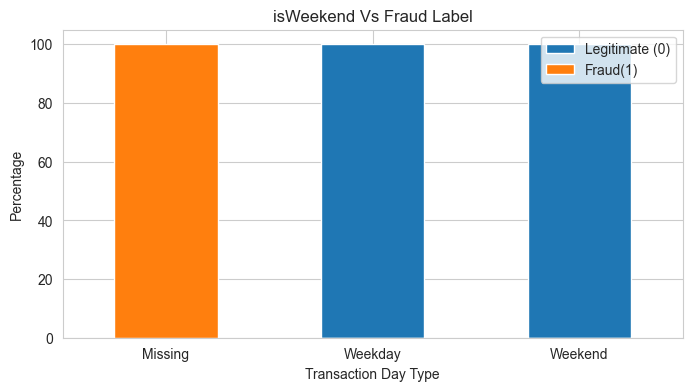

In [18]:
# 3. ISWEEKEND VS TARGET

# Include missing values as a separate category for analysis 
weekend_analysis = df_clean["isWeekend"].map({
    0 : "Weekday",
    1 : "Weekend",
}).fillna("Missing")

# Create a crosstab 
weekend_target_tabel = pd.crosstab(
    weekend_analysis,
    df_clean["label"],
    normalize = "index"
) * 100

print("\nisWeekend Vs label Percentage")
display(weekend_target_tabel)

# Plot the relationship
weekend_target_tabel.plot(
    kind = "bar",
    stacked = True,
    figsize = (8,4)
)

plt.title("isWeekend Vs Fraud Label")
plt.xlabel("Transaction Day Type")
plt.ylabel("Percentage")

plt.legend(
    ["Legitimate (0)", "Fraud(1)"]
)
plt.xticks(rotation = 0)
plt.savefig("images/isWeekend Vs Target.png", dpi=300, bbox_inches='tight')
plt.show()

In [19]:
# FRAUD RATE BY PAYMENT METHOD 

payment_fraud_rate = (
    df_clean.groupby("paymentMethod")["label"]
    .mean() * 100
)

print("\nFRAUD RATE BY PAYMENT METHOD")

display(
    payment_fraud_rate.to_frame(name = "Fraud Percentage")
)   




FRAUD RATE BY PAYMENT METHOD


,Fraud Percentage
paymentMethod,
creditcard,1.464077
paypal,1.386649
storecredit,1.097179


In [20]:
# 5.FRAUD RATE BY CATEGORY

category_fraud_rate = (
    df_clean.groupby("Category")["label"]
    .mean() * 100
)
print("\nFRAUD RATE BY CATEGORY")
display(
    category_fraud_rate.to_frame(name = "Fraud Percentage")
)    


FRAUD RATE BY CATEGORY


,Fraud Percentage
Category,
electronics,1.371357
food,1.365319
shopping,1.493097
unknown,8.421053


##### **3) MULTIVARIATE ANALYSIS**

In [21]:
# 1.) SELECT NUMERICAL FEATURE

multivariate_feature = [
    "accountAgeDays",
    "numItems",
    "localTime",
    "paymentMethodAgeDays"
]
# Add target variable for correlation analysis 
correlation_features = (
    multivariate_feature + ["label"]
)


In [22]:
# 2.) CALCULATE CORRELATION MATRIX 

# Calculate Pearson corrlation among selected numerical columns 
correlation_matrix = df_clean[
    correlation_features
].corr()

# Display corrlation matrix
print("CORRLEATION MATRIX : ")
display(correlation_matrix)

CORRLEATION MATRIX : 


,accountAgeDays,numItems,localTime,paymentMethodAgeDays,label
accountAgeDays,1.000000,-0.037562,-0.012600,0.330909,-0.128098
numItems,-0.037562,1.000000,-0.042563,0.031683,0.038116
localTime,-0.012600,-0.042563,1.000000,-0.033076,-0.059505
paymentMethodAgeDays,0.330909,0.031683,-0.033076,1.000000,-0.052047
label,-0.128098,0.038116,-0.059505,-0.052047,1.000000


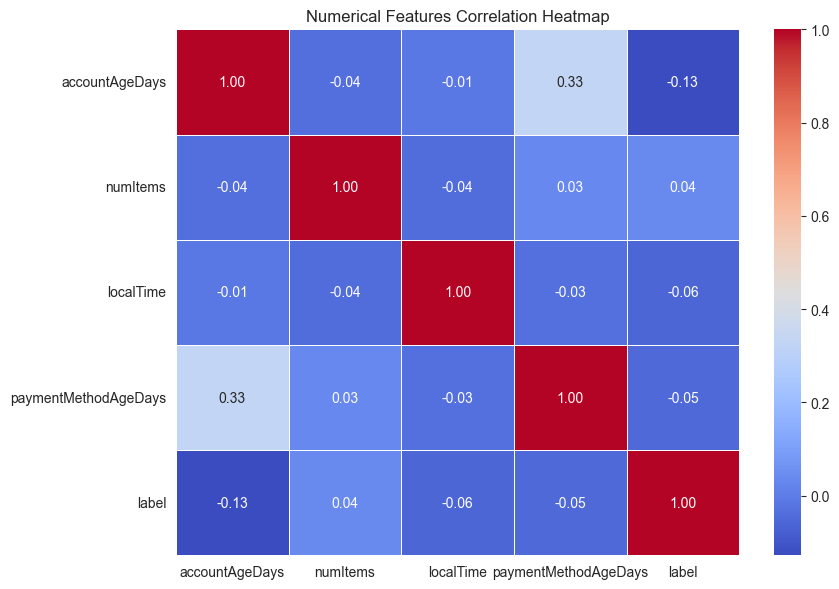

In [23]:
# 3. CORRELATION HEATMAP

plt.figure(figsize=(9,6))

# Plot Correlation matrix 
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt = ".2f",
    linewidths=0.5
)
plt.title("Numerical Features Correlation Heatmap")
plt.tight_layout()
plt.savefig("images/CORRELATION HEATMAP.png")
plt.show()

In [24]:
# 4. MULTIPLE FEATURES VS TARGET
# Compare mean values of numerical features for each target class
target_feature_summary = (
    df_clean.groupby("label")[multivariate_feature]
    .mean()
    .T
)
print("\nNUMERICAL FEATURES BY TARGET CLASS:")
display(target_feature_summary)


NUMERICAL FEATURES BY TARGET CLASS:


label,0,1
accountAgeDays,869.971211,1.000000
numItems,1.082150,1.264286
localTime,4.751020,4.555726
paymentMethodAgeDays,124.417591,0.012476


In [25]:
# 5. PAYMENT METHOD AND CATEGORY COMBINATION
# Analyze transaction counts for payment method and category 
payment_category_table = pd.crosstab(
    df_clean["paymentMethod"],
    df_clean["Category"]
)
print("\nPAYMENT METHOD VS CATEGORY:")
display(payment_category_table)


PAYMENT METHOD VS CATEGORY:


Category,electronics,food,shopping,unknown
paymentMethod,,,,
creditcard,9212,9241,9485,66
paypal,3015,3077,3182,29
storecredit,607,646,661,0



COMBINED PAYMENT METHOD AND CATEGORY FRAUD RATE : 


Category,electronics,food,shopping,unknown
paymentMethod,,,,
creditcard,1.389492,1.417595,1.528730,9.090909
paypal,1.359867,1.299968,1.445632,6.896552
storecredit,1.153213,0.928793,1.210287,NaN


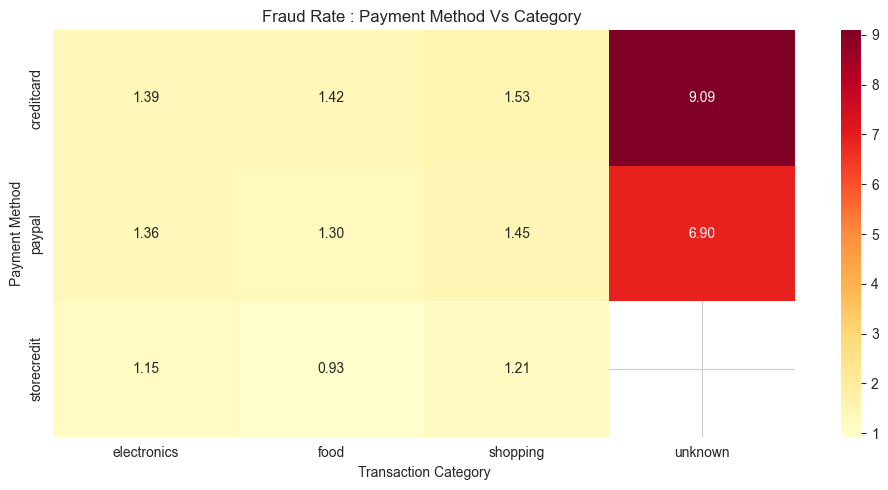

In [26]:
# 6. PAYMENT METHOD + CATEGORY VS FRAUD RATE
# Calculate fraud rate for each payment / category combination 
combined_fraud_rate = (
    df_clean.groupby(
        ["paymentMethod" , "Category"]
    )["label"]
    .mean()
    .mul(100)
    .unstack()
)
print("\nCOMBINED PAYMENT METHOD AND CATEGORY FRAUD RATE : ")
display(combined_fraud_rate)

# Plot the combined fraud rates
plt.figure(figsize=(10,5))
sns.heatmap(
    combined_fraud_rate,
    annot=True,
    cmap= "YlOrRd",
    fmt = ".2f"
)
plt.title("Fraud Rate : Payment Method Vs Category ")
plt.xlabel("Transaction Category")
plt.ylabel("Payment Method")
plt.tight_layout()
plt.savefig("images/Fraud Rate : Payment Method Vs Category.png")
plt.show()

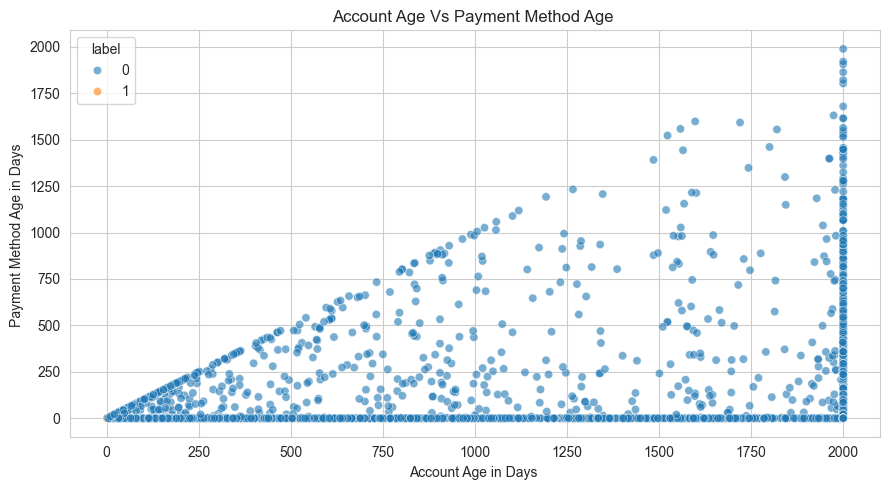

In [27]:
# 7. ACCOUNT AGE VS PAYMENT METHOD AGE

# Use a sample to make the scatter plot easier to read 
scatter_data = df_clean.sample(
    n=min(3000, len(df_clean)),
    random_state=42
)
plt.figure(figsize=(9,5))
sns.scatterplot(
    data= scatter_data,
    x = "accountAgeDays",
    y = "paymentMethodAgeDays",
    hue = "label",
    alpha = 0.6
)
plt.title("Account Age Vs Payment Method Age ")
plt.xlabel("Account Age in Days ")
plt.ylabel("Payment Method Age in Days ")
plt.tight_layout()
plt.savefig("images/Account Age vs Payment Method Age.png")
plt.show()

In [28]:
# 8. INVESTIGATE ISWEEKEND MISSINGNESS
# Check whether missing isWeekend values are associated with target
weekend_missing_analysis = pd.crosstab(
    df_clean["isWeekend"].isna(),
    df_clean["label"],
    normalize="columns"
) * 100

print("\nISWEEKEND MISSINGNESS VS TARGET : ")
display(weekend_missing_analysis)


ISWEEKEND MISSINGNESS VS TARGET : 


label,0,1
isWeekend,,
False,100.0,0.0
True,0.0,100.0


##### **4) Statistical Analysis :**

In [29]:
# 1) Descriptive Statistics

# Numerical Statistical Summary 
statistical_summary = df_clean[numeric_columns].describe().T
print("NUMERICAL STATISTICAL SUMMARY : ")
display(statistical_summary)

NUMERICAL STATISTICAL SUMMARY : 


,count,mean,std,min,25%,50%,75%,max
accountAgeDays,39221.0,857.563984,804.788212,1.000000,72.000000,603.000000,1804.000000,2000.000000
numItems,39221.0,1.084751,0.566899,1.000000,1.000000,1.000000,1.000000,29.000000
localTime,39221.0,4.748232,0.389360,0.421214,4.742303,4.886641,4.962055,5.040929
paymentMethodAgeDays,39221.0,122.641326,283.569177,0.000000,0.000000,0.012500,87.510417,1999.580556


In [30]:
# 2) Skewness Analysis
# Calculate skewness 
skewness = df_clean[numeric_columns].skew()
print("SKEWNESS OF NUMERICAL FEATURES")
display(skewness.sort_values(ascending=False))

SKEWNESS OF NUMERICAL FEATURES


numItems                13.335984
paymentMethodAgeDays     3.237163
accountAgeDays           0.360457
localTime               -2.953502
dtype: float64

In [31]:
# 3) Fraud vs Legitimate Mean and Median
# Compare numerical features by target label 
group_statistics = df_clean.groupby("label")[numeric_columns].agg(
    ["mean" , "median" , "std"]
)
display(group_statistics)

accountAgeDays                     numItems                  localTime  \
                mean median         std      mean median       std      mean   
label                                                                          
0         869.971211  625.0  803.917989  1.082150    1.0  0.564218  4.751020   
1           1.000000    1.0    0.000000  1.264286    1.0  0.706329  4.555726   

                          paymentMethodAgeDays                        
         median       std                 mean    median         std  
label                                                                 
0      4.886641  0.384536           124.417591  0.017361  285.228464  
1      4.748314  0.610253             0.012476  0.000000    0.081981

In [32]:
# Define Categorical Features
categorical_cols = [
    "paymentMethod",
    "Category"
]

print("Categorical Features:", categorical_cols)

Categorical Features: ['paymentMethod', 'Category']


In [33]:
# 4) Chi-Square Test for Categorical Features

from scipy.stats import chi2_contingency

for col in categorical_cols:

    contingency_table = pd.crosstab(
        df_clean[col],
        df_clean["label"]
    )

    chi2, p_value, dof, expected = chi2_contingency(
        contingency_table
    )

    print("\nFeature:", col)
    print("Chi-Square:", chi2)
    print("P-Value:", p_value)

    if p_value < 0.05:
        print("Result: Statistically significant association")
    else:
        print("Result: No statistically significant association")


Feature: paymentMethod
Chi-Square: 1.8603295880806863
P-Value: 0.39448869562870487
Result: No statistically significant association

Feature: Category
Chi-Square: 34.06482842297048
P-Value: 1.9197273279568933e-07
Result: Statistically significant association


#### **Step No 7 : Target Variable Analysis :** 

In [34]:
# 1) Target Count

target_counts = (
    df_clean["label"]
    .value_counts()
    .sort_index()
)

print("TARGET VARIABLE COUNT")
display(target_counts)

TARGET VARIABLE COUNT


label
0    38661
1      560
Name: count, dtype: int64

In [35]:
# 2) Target Percentage

target_percentage = (
    df_clean["label"]
    .value_counts(normalize=True)
    .sort_index() * 100
)

print("TARGET VARIABLE PERCENTAGE")

display(
    target_percentage.to_frame(
        name="Percentage (%)"
    ).round(2)
)

TARGET VARIABLE PERCENTAGE


,Percentage (%)
label,
0,98.57
1,1.43


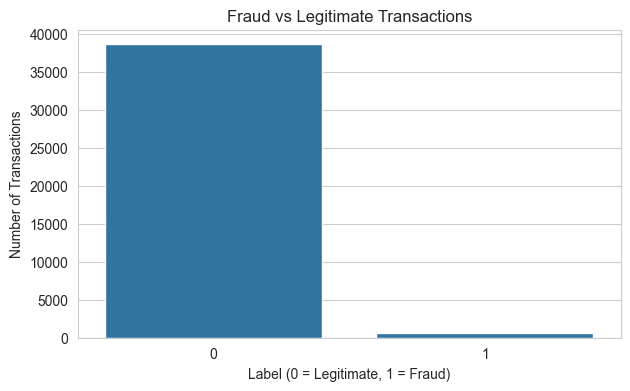

In [36]:
# 3)Target Visualization
plt.figure(figsize=(7, 4))

sns.countplot(
    data=df_clean,
    x="label"
)

plt.title("Fraud vs Legitimate Transactions")
plt.xlabel("Label (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Number of Transactions")

plt.show()

In [37]:
# 4) Class Imbalance Ratio
legitimate_count = (df_clean["label"] == 0).sum()
fraud_count = (df_clean["label"] == 1).sum()

imbalance_ratio = legitimate_count / fraud_count

print("Legitimate Transactions:", legitimate_count)
print("Fraud Transactions:", fraud_count)
print("Class Imbalance Ratio:", round(imbalance_ratio, 2))

Legitimate Transactions: 38661
Fraud Transactions: 560
Class Imbalance Ratio: 69.04


In [38]:
# 5) Fraud Percentage

fraud_count = (df_clean["label"] == 1).sum()

fraud_percentage = (
    fraud_count / len(df_clean)
) * 100

print("Total Fraud Transactions:", fraud_count)
print("Fraud Percentage:", round(fraud_percentage, 2), "%")

Total Fraud Transactions: 560
Fraud Percentage: 1.43 %


##### **Step No 8 : Feature Engineering**

In [39]:
# 1: Create New Features :

# Create a separate copy for feature engineering 
df_fe = df_clean.copy()

# 1. Log transformation of account age 
df_fe["account_age_log"] = np.log1p(
    df_fe["accountAgeDays"]
)

# 2. Log transformation of payment method age 
df_fe["payment_age_log"] = np.log1p(
    df_fe["paymentMethodAgeDays"]
)

# 3. Account and payment method age ratio
df_fe["account_payment_age_ratio"] = (
    df_fe["paymentMethodAgeDays"] / 
    df_fe["accountAgeDays"].clip(lower=1)
)

# 4. Difference between account age and payment method age 
df_fe["account_payment_age_gap"] = (
    df_fe["accountAgeDays"] - 
    df_fe["paymentMethodAgeDays"]
)

# 5. payment method age zero indicator 
df_fe["payment_age_zero_flag"] = (
    df_fe["paymentMethodAgeDays"] == 0
).astype(int)

# 6. Number of items grouping 
df_fe["item_group"] = pd.cut(
    df_fe["numItems"] , 
    bins=[0,1,5,np.inf],
    labels=["Single" , "Few" , "Multiple"]
)

# Display new features
new_features = [
    "account_age_log",
    "payment_age_log",
    "account_payment_age_ratio",
    "account_payment_age_gap",
    "payment_age_zero_flag",
    "item_group"
]

display(df_fe[new_features].head())

,account_age_log,payment_age_log,account_payment_age_ratio,account_payment_age_gap,payment_age_zero_flag,item_group
0,3.401197,3.374335,0.972581,0.795139,0,Single
1,6.587550,0.000000,0.000000,725.000000,1,Single
2,6.740519,0.000000,0.000000,845.000000,1,Single
3,6.222576,0.000000,0.000000,503.000000,1,Single
4,7.601402,0.000000,0.000000,2000.000000,1,Single


In [40]:
# 2: Check Engineered Features : 

print("NEW FEATURES INFORMATION")

display(df_fe[new_features].describe(include="all").T)

print("\nMissing Values in New Features")

display(df_fe[new_features].isnull().sum())

print("\nNegative Account-Payment Age Gap")

print(
    (df_fe["account_payment_age_gap"] < 0).sum()
)

NEW FEATURES INFORMATION


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
account_age_log,39221.0,NaN,NaN,NaN,5.627288,2.067741,0.693147,4.290459,6.403574,7.498316,7.601402
payment_age_log,39221.0,NaN,NaN,NaN,1.962658,2.530652,0.0,0.0,0.012423,4.48312,7.601193
account_payment_age_ratio,39221.0,NaN,NaN,NaN,0.232455,0.365212,0.0,0.0,0.000092,0.369043,0.999995
account_payment_age_gap,39221.0,NaN,NaN,NaN,734.922657,759.644529,0.002083,18.0,434.0,1476.0,2000.0
payment_age_zero_flag,39221.0,NaN,NaN,NaN,0.35458,0.478392,0.0,0.0,0.0,1.0,1.0
item_group,39221,3,Single,37398,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Missing Values in New Features


account_age_log              0
payment_age_log              0
account_payment_age_ratio    0
account_payment_age_gap      0
payment_age_zero_flag        0
item_group                   0
dtype: int64


Negative Account-Payment Age Gap
0


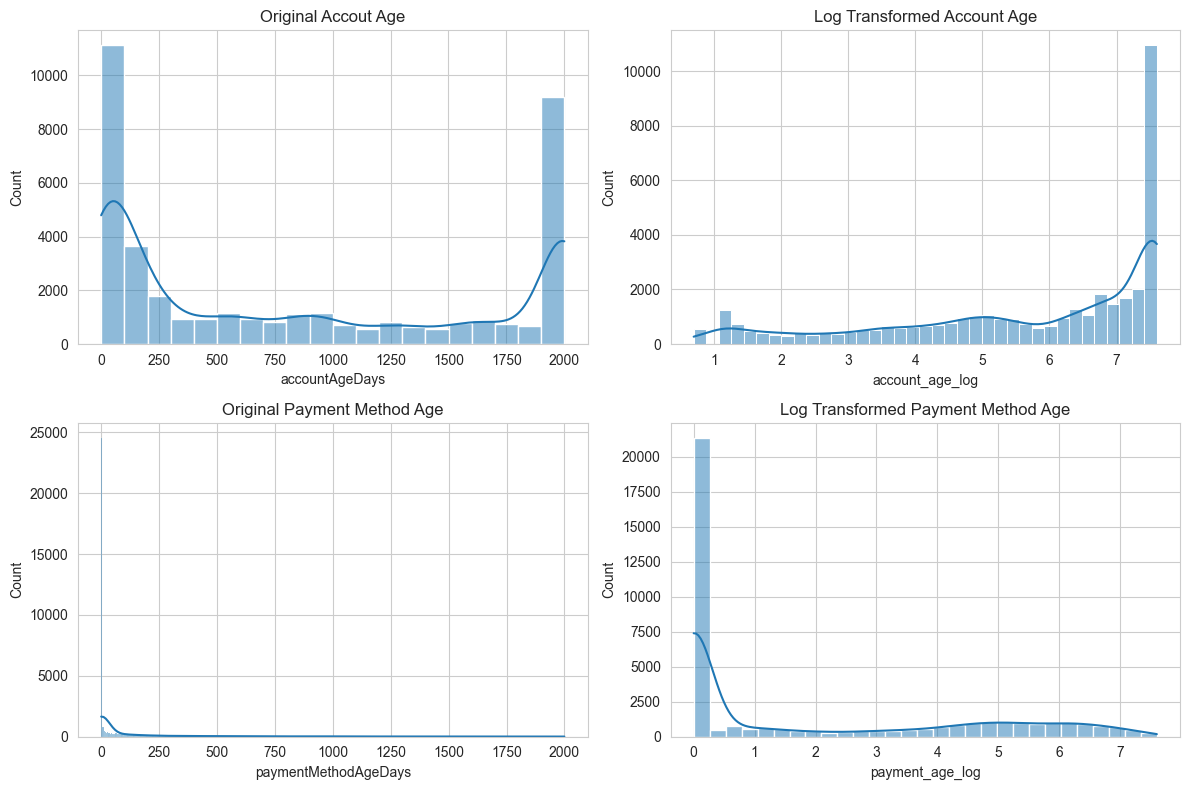

In [41]:
# 3: Compare Original and Transformed Features : 

fig , axes = plt.subplots(2,2, figsize = (12,8))

sns.histplot(
    df_fe["accountAgeDays"],
    kde=True,
    ax = axes[0,0]
)
axes[0,0].set_title("Original Accout Age")

sns.histplot(
    df_fe["account_age_log"],
    kde = True,
    ax = axes[0,1]
)
axes[0,1].set_title("Log Transformed Account Age")

sns.histplot(
    df_fe["paymentMethodAgeDays"],
    kde=True,
    ax = axes[1,0]
)
axes[1,0].set_title("Original Payment Method Age")

sns.histplot(
    df_fe["payment_age_log"],
    kde = True,
    ax=axes[1,1]
)
axes[1, 1].set_title("Log Transformed Payment Method Age")

plt.tight_layout()
plt.show()

In [42]:
# 4: Fraud Rate by New Features

# Fraud rate by item group
item_group_fraud = df_fe.groupby(
    "item_group",
    observed=False
)["label"].mean() * 100

print("Fraud Rate by Item Group")
display(item_group_fraud)

# Fraud rate by payment age zero flag
payment_zero_fraud = df_fe.groupby(
    "payment_age_zero_flag"
)["label"].mean() * 100
print("\nFraud Rate by Payment Age Zero Flag")
display(payment_zero_fraud)

Fraud Rate by Item Group


item_group
Single      1.213969
Few         6.097561
Multiple    0.990099
Name: label, dtype: float64


Fraud Rate by Payment Age Zero Flag


payment_age_zero_flag
0    1.046852
1    2.121234
Name: label, dtype: float64

##### **Step No 9 : Feature Selection :** 

In [43]:
# 1: Select Candidate Features

# Original numerical features 
original_numerical_features = [
    "accountAgeDays",
    "numItems",
    "localTime",
    "paymentMethodAgeDays"
]

# Engineered numerical features
engineered_numerical_feature = [
    "account_age_log",
    "payment_age_log",
    "account_payment_age_ratio",
    "account_payment_age_gap",
    "payment_age_zero_flag"
]

# Categorical features 
categorical_features = [
    "paymentMethod",
    "Category",
    "item_group"
]

# Combines all candidate features
selected_features = (
    original_numerical_features +
    engineered_numerical_feature + 
    categorical_features
)

# Separete X and y 

X_candidate = df_fe[selected_features].copy()
y = df_fe["label"].copy()

print("Candidate Features : ")
print(selected_features)

print("\nTotal Candidate Features:", len(selected_features))

print("\nX Shape:", X_candidate.shape)
print("y Shape:", y.shape)

Candidate Features : 
['accountAgeDays', 'numItems', 'localTime', 'paymentMethodAgeDays', 'account_age_log', 'payment_age_log', 'account_payment_age_ratio', 'account_payment_age_gap', 'payment_age_zero_flag', 'paymentMethod', 'Category', 'item_group']

Total Candidate Features: 12

X Shape: (39221, 12)
y Shape: (39221,)


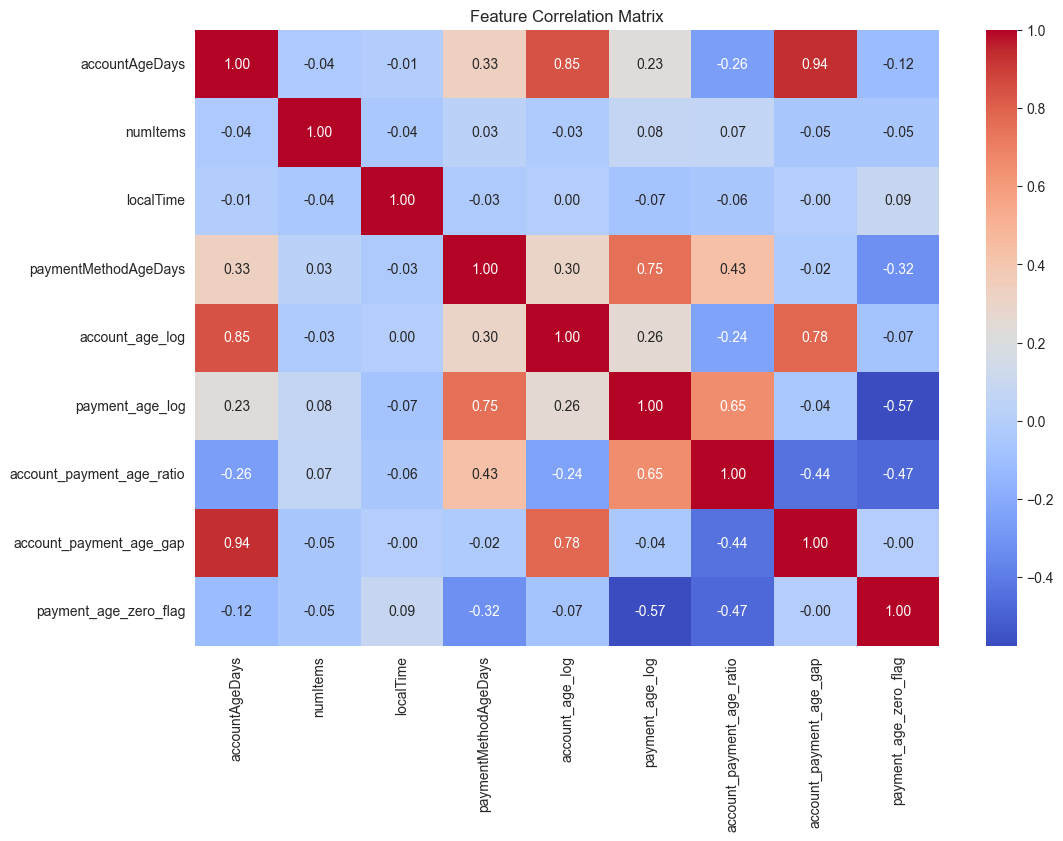

In [44]:
# 2: Check Feature Correlation : 
# Select numerical candidate features
numeric_candidate_features = (
    original_numerical_features +
    engineered_numerical_feature
)

correlation_matrix = df_fe[
    numeric_candidate_features
].corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Feature Correlation Matrix")

plt.show()

In [45]:
# 3: Final Candidate Feature Check : 

# Check missing values in candidate features
print("Missing Values:")

display(X_candidate.isnull().sum())

# Check data types
print("\nFeature Data Types:")

display(X_candidate.dtypes)

# Check target distribution
print("\nTarget Distribution:")

display(y.value_counts())

Missing Values:


accountAgeDays               0
numItems                     0
localTime                    0
paymentMethodAgeDays         0
account_age_log              0
payment_age_log              0
account_payment_age_ratio    0
account_payment_age_gap      0
payment_age_zero_flag        0
paymentMethod                0
Category                     0
item_group                   0
dtype: int64


Feature Data Types:


accountAgeDays                        int64
numItems                              int64
localTime                           float64
paymentMethodAgeDays                float64
account_age_log                     float64
payment_age_log                     float64
account_payment_age_ratio           float64
account_payment_age_gap             float64
payment_age_zero_flag                 int64
paymentMethod                string[python]
Category                     string[python]
item_group                         category
dtype: object


Target Distribution:


label
0    38661
1      560
Name: count, dtype: int64

##### **Step No 10 : Train-Test Split**

In [46]:
# Import StratifiedGroupKFold
from sklearn.model_selection import StratifiedGroupKFold

# Create groups using identical feature combinations
groups = pd.util.hash_pandas_object(
    X_candidate,
    index=False
)

# Initialize Stratified Group Split
group_split = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Generate Train-Test indices
train_idx, test_idx = next(
    group_split.split(
        X_candidate,
        y,
        groups=groups
    )
)

# Create new Training and Testing Data
X_train = X_candidate.iloc[train_idx].copy()
X_test = X_candidate.iloc[test_idx].copy()

y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()

# Display shapes
print("Training Shape:", X_train.shape)
print("Testing Shape:", X_test.shape)

print("\nTraining Target Distribution:")
display(y_train.value_counts())

print("\nTesting Target Distribution:")
display(y_test.value_counts())

Training Shape: (31324, 12)
Testing Shape: (7897, 12)

Training Target Distribution:


label
0    30877
1      447
Name: count, dtype: int64


Testing Target Distribution:


label
0    7784
1     113
Name: count, dtype: int64

In [47]:
# Check Target Percentage

print("Training Target Percentage:")
display(y_train.value_counts(normalize=True) * 100)

print("\nTesting Target Percentage:")
display(y_test.value_counts(normalize=True) * 100)

Training Target Percentage:


label
0    98.572979
1     1.427021
Name: proportion, dtype: float64


Testing Target Percentage:


label
0    98.569077
1     1.430923
Name: proportion, dtype: float64

##### Check Missing Values

In [48]:
# Check Missing Values

print("Training Data Missing Values:")
display(X_train.isnull().sum())

print("\nTesting Data Missing Values:")
display(X_test.isnull().sum())

Training Data Missing Values:


accountAgeDays               0
numItems                     0
localTime                    0
paymentMethodAgeDays         0
account_age_log              0
payment_age_log              0
account_payment_age_ratio    0
account_payment_age_gap      0
payment_age_zero_flag        0
paymentMethod                0
Category                     0
item_group                   0
dtype: int64


Testing Data Missing Values:


accountAgeDays               0
numItems                     0
localTime                    0
paymentMethodAgeDays         0
account_age_log              0
payment_age_log              0
account_payment_age_ratio    0
account_payment_age_gap      0
payment_age_zero_flag        0
paymentMethod                0
Category                     0
item_group                   0
dtype: int64

##### 1)Train-Test Data Leakage Check (Duplicate Record Overlap)

In [49]:
# Duplicate Leakage Check

train_unique = X_train.drop_duplicates()
test_unique = X_test.drop_duplicates()

overlap_records = train_unique.merge(
    test_unique,
    how="inner"
)

print(
    "Common Feature Records:",
    len(overlap_records)
)

Common Feature Records: 0


##### 2)Duplicate Feature Combination & Target Label Consistency Check

In [50]:
# Add Target Labels to Training and Testing Data

train_check = X_train.copy()
train_check["label"] = y_train.values

test_check = X_test.copy()
test_check["label"] = y_test.values

# Remove exact duplicate rows within each dataset
train_check = train_check.drop_duplicates()
test_check = test_check.drop_duplicates()

# Find common feature combinations
common_records = train_check.merge(
    test_check,
    on=list(X_train.columns),
    suffixes=("_train", "_test")
)

# Compare target labels
same_label = (
    common_records["label_train"] ==
    common_records["label_test"]
)

print("Common Feature Combinations:", len(common_records))

print("Same Label Records:", same_label.sum())

print("Different Label Records:", (~same_label).sum())

Common Feature Combinations: 0
Same Label Records: 0
Different Label Records: 0


##### 3) Train-Test Data Overlap Percentage Analysis

In [51]:
# Calculate Train-Test Overlap Percentage

overlap_percentage = (
    len(common_records) / len(test_unique)
) * 100

print(
    "Test Data Unique Records:",
    len(test_unique)
)

print(
    "Overlap Percentage:",
    round(overlap_percentage, 2),
    "%"
)

Test Data Unique Records: 7077
Overlap Percentage: 0.0 %


##### **Step No 11 : Data Processing :** 

##### 1) Importing Required Libraries

In [ ]:
# Import SimpleImputer for handling missing values
from sklearn.impute import SimpleImputer

# Import preprocessing techniques
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Import ColumnTransformer for column-wise preprocessing
from sklearn.compose import ColumnTransformer

# Import Pipeline for combining preprocessing steps
from sklearn.pipeline import Pipeline

# Print success message
print("Preprocessing Libraries Imported Successfully!")

Preprocessing Libraries Imported Successfully!


##### 2) Feature Selection – Numerical & Categorical Features 

In [53]:
# Numerical Features
numeric_features = [
    "accountAgeDays",
    "numItems",
    "localTime",
    "paymentMethodAgeDays",
    "account_age_log",
    "payment_age_log",
    "account_payment_age_ratio",
    "account_payment_age_gap",
    "payment_age_zero_flag"
]

# Categorical Features
categorical_features = [
    "paymentMethod",
    "Category",
    "item_group"
]

print("Numerical Features:", numeric_features)
print("\nCategorical Features:", categorical_features)

Numerical Features: ['accountAgeDays', 'numItems', 'localTime', 'paymentMethodAgeDays', 'account_age_log', 'payment_age_log', 'account_payment_age_ratio', 'account_payment_age_gap', 'payment_age_zero_flag']

Categorical Features: ['paymentMethod', 'Category', 'item_group']


##### 3) Categorical Data Type Conversion & Missing Value Handling

In [54]:
# Convert Categorical Features to Object Type

for col in categorical_features:
    X_train[col] = X_train[col].astype("object")
    X_test[col] = X_test[col].astype("object")

# Handle Missing Categorical Values
X_train[categorical_features] = (
    X_train[categorical_features].fillna("Unknown")
)

X_test[categorical_features] = (
    X_test[categorical_features].fillna("Unknown")
)

print("Training Missing Values:")
display(X_train.isnull().sum())

print("\nTesting Missing Values:")
display(X_test.isnull().sum())

Training Missing Values:


accountAgeDays               0
numItems                     0
localTime                    0
paymentMethodAgeDays         0
account_age_log              0
payment_age_log              0
account_payment_age_ratio    0
account_payment_age_gap      0
payment_age_zero_flag        0
paymentMethod                0
Category                     0
item_group                   0
dtype: int64


Testing Missing Values:


accountAgeDays               0
numItems                     0
localTime                    0
paymentMethodAgeDays         0
account_age_log              0
payment_age_log              0
account_payment_age_ratio    0
account_payment_age_gap      0
payment_age_zero_flag        0
paymentMethod                0
Category                     0
item_group                   0
dtype: int64

In [ ]:
# 4) Numerical Preprocessing Pipeline


numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

print("Numerical Preprocessing Pipeline Created Successfully!")

Numerical Preprocessing Pipeline Created Successfully!


In [ ]:
# 5) Categorical Preprocessing Pipeline


categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(
            strategy="constant",
            fill_value="Unknown"
        )),
        ("encoder", OneHotEncoder(
            handle_unknown="ignore"
        ))
    ]
)

print("Categorical Preprocessing Pipeline Created Successfully!")

Categorical Preprocessing Pipeline Created Successfully!


In [ ]:
# 6) Create Column Transformer

# Combine Numerical and Categorical Preprocessing

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing Pipeline Created Successfully!")

Preprocessing Pipeline Created Successfully!


In [ ]:
# 7) Check Preprocessor Configuration

print("Numerical Features:", numeric_features)
print("Categorical Features:", categorical_features)

print("\nPreprocessor Configuration:")
print(preprocessor)

Numerical Features: ['accountAgeDays', 'numItems', 'localTime', 'paymentMethodAgeDays', 'account_age_log', 'payment_age_log', 'account_payment_age_ratio', 'account_payment_age_gap', 'payment_age_zero_flag']
Categorical Features: ['paymentMethod', 'Category', 'item_group']

Preprocessor Configuration:
ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['accountAgeDays', 'numItems', 'localTime',
                                  'paymentMethodAgeDays', 'account_age_log',
                                  'payment_age_log',
                                  'account_payment_age_ratio',
                                  'account_payment_age_gap',
                                  'payment_age_zero_flag']),
                                ('cat',

##### **Step No 12) Imbalanced Data Handling**

In [59]:
# 1: Class Distribution

# Count Training Classes

legitimate_count = (y_train == 0).sum()
fraud_count = (y_train == 1).sum()

# Calculate Imbalance Ratio
class_ratio = legitimate_count / fraud_count

print("Legitimate Transactions:", legitimate_count)
print("Fraud Transactions:", fraud_count)

print("Class Imbalance Ratio:", round(class_ratio, 2))

Legitimate Transactions: 30877
Fraud Transactions: 447
Class Imbalance Ratio: 69.08


In [60]:
# 2 – Class Weight Calculation :

from sklearn.utils.class_weight import compute_class_weight

# Identify Classes
classes = np.unique(y_train)

# Calculate Balanced Class Weights
weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

# Create Class Weight Dictionary
class_weights = dict(zip(classes, weights))

print("Class Weights:")
print(class_weights)

Class Weights:
{np.int64(0): np.float64(0.5072383975127117), np.int64(1): np.float64(35.038031319910516)}


##### **Step No 13 : SMOTENC Oversampling :**

In [ ]:


%pip install imbalanced-learn

Note: you may need to restart the kernel to use updated packages.


In [62]:
# 1 – Import SMOTENC

from imblearn.over_sampling import SMOTENC
from sklearn.impute import SimpleImputer

print("SMOTENC Libraries Imported Successfully!")

SMOTENC Libraries Imported Successfully!


In [63]:
# 2 – Prepare Training Data for SMOTENC

# Copy Training Data Only
X_train_smote_input = X_train.copy()

# Numerical Missing Value Imputation
smote_numeric_imputer = SimpleImputer(strategy="median")

X_train_smote_input[numeric_features] = (
    smote_numeric_imputer.fit_transform(
        X_train_smote_input[numeric_features]
    )
)

print("SMOTENC Training Data Prepared Successfully!")

print("\nMissing Values:")
display(X_train_smote_input.isnull().sum())

SMOTENC Training Data Prepared Successfully!

Missing Values:


accountAgeDays               0
numItems                     0
localTime                    0
paymentMethodAgeDays         0
account_age_log              0
payment_age_log              0
account_payment_age_ratio    0
account_payment_age_gap      0
payment_age_zero_flag        0
paymentMethod                0
Category                     0
item_group                   0
dtype: int64

In [64]:
# 3 – Identify Categorical Column Positions
# Identify Categorical Feature Positions

categorical_indices = [
    X_train_smote_input.columns.get_loc(col)
    for col in categorical_features
]

print("Categorical Feature Names:", categorical_features)
print("Categorical Feature Positions:", categorical_indices)

Categorical Feature Names: ['paymentMethod', 'Category', 'item_group']
Categorical Feature Positions: [9, 10, 11]


In [65]:
# 4 – Apply SMOTENC Oversampling

# Create SMOTENC Object

smotenc = SMOTENC(
    categorical_features=categorical_indices,
    sampling_strategy=0.5,
    random_state=42,
    k_neighbors=5
)

# Apply SMOTENC on Training Data Only

X_train_resampled, y_train_resampled = smotenc.fit_resample(
    X_train_smote_input,
    y_train
)

print("SMOTENC Oversampling Completed Successfully!")

SMOTENC Oversampling Completed Successfully!


In [66]:
# 5 Compare Class Distribution
# Original Training Data Distribution
print("Original Training Data Shape:", X_train.shape)

print("\nOriginal Class Distribution:")
display(y_train.value_counts().sort_index())

# Resampled Training Data Distribution
print("\nResampled Training Data Shape:", X_train_resampled.shape)

print("\nResampled Class Distribution:")
display(pd.Series(y_train_resampled).value_counts().sort_index())

Original Training Data Shape: (31324, 12)

Original Class Distribution:


label
0    30877
1      447
Name: count, dtype: int64


Resampled Training Data Shape: (46315, 12)

Resampled Class Distribution:


label
0    30877
1    15438
Name: count, dtype: int64

##### **Step No 14 : Baseline Model** 

In [67]:
# 1) Import DummyClassifier
from sklearn.dummy import DummyClassifier

print("Baseline Model Libraries Imported Successfully!")

Baseline Model Libraries Imported Successfully!


In [68]:
# 2) Create Baseline Model
# Create Baseline Model

baseline_model = DummyClassifier(
    strategy="most_frequent"
)

print("Baseline Model Created Successfully!")

Baseline Model Created Successfully!


In [69]:
# 3) Train Baseline Model
# Train Baseline Model

baseline_model.fit(
    np.zeros((len(y_train), 1)),
    y_train
)

print("Baseline Model Training Completed!")

Baseline Model Training Completed!


In [70]:
# 4) Predict Test Data
# Predict Test Data

baseline_predictions = baseline_model.predict(
    np.zeros((len(y_test), 1))
)

print("Baseline Predictions:")
print(baseline_predictions[:20])

Baseline Predictions:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


##### **Step No 15 : Model Building :**

##### *1) Model -Logistic Regression :*

In [72]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.base import clone

print("Logistic Regression Libraries Imported Successfully!")

Logistic Regression Libraries Imported Successfully!


In [73]:
# Create Model Pipeline : 

logistic_model = Pipeline(
    steps=[
        ("preprocessor", clone(preprocessor)),
        ("classifier", LogisticRegression(
            class_weight="balanced",
            max_iter=2000,
            random_state=42
        ))
    ]
)

print("Logistic Regression Pipeline Created Successfully!")

Logistic Regression Pipeline Created Successfully!


In [74]:
# 3 – Train Model
logistic_model.fit(
    X_train,
    y_train
)

print("Logistic Regression Model Trained Successfully!")

Logistic Regression Model Trained Successfully!


In [75]:
# 4 – Predict Test Data
logistic_predictions = logistic_model.predict(X_test)

print("Logistic Regression Predictions:")
print(logistic_predictions[:20])

Logistic Regression Predictions:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


##### *2) Model – Decision Tree Classifier*

In [76]:
# 1 – Import Library
from sklearn.tree import DecisionTreeClassifier

print("Decision Tree Library Imported Successfully!")

Decision Tree Library Imported Successfully!


In [77]:
# 2 – Create Model Pipeline
decision_tree_model = Pipeline(
    steps=[
        ("preprocessor", clone(preprocessor)),
        ("classifier", DecisionTreeClassifier(
            class_weight="balanced",
            max_depth=8,
            min_samples_split=10,
            min_samples_leaf=5,
            random_state=42
        ))
    ]
)

print("Decision Tree Pipeline Created Successfully!")

Decision Tree Pipeline Created Successfully!


In [78]:
# 3 – Train Model
decision_tree_model.fit(
    X_train,
    y_train
)

print("Decision Tree Model Trained Successfully!")

Decision Tree Model Trained Successfully!


In [79]:
# 4 – Predict Test Data
decision_tree_predictions = decision_tree_model.predict(X_test)

print("Decision Tree Predictions:")
print(decision_tree_predictions[:20])

Decision Tree Predictions:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


##### *3) Model - Random Forest Classifier*

In [80]:
# 1 – Import Library
from sklearn.ensemble import RandomForestClassifier

print("Random Forest Library Imported Successfully!")

Random Forest Library Imported Successfully!


In [81]:
# 2 – Create Model Pipeline
random_forest_model = Pipeline(
    steps=[
        ("preprocessor", clone(preprocessor)),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            max_depth=12,
            min_samples_split=10,
            min_samples_leaf=3,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ))
    ]
)

print("Random Forest Pipeline Created Successfully!")

Random Forest Pipeline Created Successfully!


In [82]:
# 3 – Train Model
random_forest_model.fit(
    X_train,
    y_train
)

print("Random Forest Model Trained Successfully!")

Random Forest Model Trained Successfully!


In [83]:
# 4 – Predict Test Data

random_forest_predictions = random_forest_model.predict(X_test)

print("Random Forest Predictions:")
print(random_forest_predictions[:20])

Random Forest Predictions:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


##### *4)  Create SMOTENC Random Forest Pipeline*

In [84]:
# 1 – Create SMOTENC Random Forest Pipeline
random_forest_smote_model = Pipeline(
    steps=[
        ("preprocessor", clone(preprocessor)),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            max_depth=12,
            min_samples_split=10,
            min_samples_leaf=3,
            random_state=42,
            n_jobs=-1
        ))
    ]
)

print("Random Forest SMOTENC Pipeline Created Successfully!")

Random Forest SMOTENC Pipeline Created Successfully!


In [85]:
# 2 – Train Model
random_forest_smote_model.fit(
    X_train_resampled,
    y_train_resampled
)

print("Random Forest with SMOTENC Trained Successfully!")

Random Forest with SMOTENC Trained Successfully!


In [86]:
# 3 – Predict Test Data
random_forest_smote_predictions = (
    random_forest_smote_model.predict(X_test)
)

print("Random Forest SMOTENC Predictions:")
print(random_forest_smote_predictions[:20])

Random Forest SMOTENC Predictions:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


##### *5) Model – XGBoost Classifier*

In [87]:
# 1 – Import XGBoost
%pip install xgboost

   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/48.9 MB ? eta -:--:--
   - -------------------------------------- 1.8/48.9 MB 7.2 MB/s eta 0:00:07
   - -------------------------------------- 2.4/48.9 MB 4.8 MB/s eta 0:00:10
   - -------------------------------------- 2.4/48.9 MB 4.8 MB/s eta 0:00:10
   -- ------------------------------------- 2.9/48.9 MB 3.4 MB/s eta 0:00:14
   -- ------------------------------------- 3.4/48.9 MB 3.1 MB/s eta 0:00:15
   --- ------------------------------------ 3.9/48.9 MB 3.0 MB/s eta 0:00:15
   --- ------------------------------------ 4.5/48.9 MB 3.0 MB/s eta 0:00:15
   ---- ----------------------------------- 5.0/48.9 MB 2.9 MB/s eta 0:00:15
   ---- ----------------------------------- 5.5/48.9 MB 2.8 MB/s eta 0:00:16
   ---- ----------------------------------- 5.8/48.9 MB 2.7 MB/s eta 0:00:17
   ----- ---------------------------------- 6.6/48.9 MB 2.7 MB/s eta 0:00:16
   ----- ----

In [88]:
from xgboost import XGBClassifier

print("XGBoost Library Imported Successfully!")

XGBoost Library Imported Successfully!


In [89]:
# 2 – Calculate Scale Positive Weight
scale_pos_weight = (
    (y_train == 0).sum() /
    (y_train == 1).sum()
)

print("Scale Positive Weight:", round(scale_pos_weight, 2))

Scale Positive Weight: 69.08


In [90]:
# 3 – Create XGBoost Model Pipeline
# Create XGBoost Model Pipeline

xgboost_model = Pipeline(
    steps=[
        ("preprocessor", clone(preprocessor)),
        ("classifier", XGBClassifier(
            n_estimators=300,
            learning_rate=0.05,
            max_depth=5,
            subsample=0.8,
            colsample_bytree=0.8,
            scale_pos_weight=scale_pos_weight,
            eval_metric="logloss",
            random_state=42,
            n_jobs=-1
        ))
    ]
)

print("XGBoost Pipeline Created Successfully!")

XGBoost Pipeline Created Successfully!


In [91]:
# 4 – Train XGBoost Model
xgboost_model.fit(
    X_train,
    y_train
)

print("XGBoost Model Trained Successfully!")

XGBoost Model Trained Successfully!


In [92]:
# 5 – Predict Test Data
xgboost_predictions = xgboost_model.predict(X_test)

print("XGBoost Predictions:")
print(xgboost_predictions[:20])

XGBoost Predictions:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


##### **Step No 16 : Model Performance Evaluation**

In [93]:
# 1 – Import Evaluation Metrics

# Import Model Evaluation Metrics

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

print("Model Evaluation Libraries Imported Successfully!")

Model Evaluation Libraries Imported Successfully!


In [94]:
# 2 – Check All Model Predictions

# Store All Model Predictions

models_predictions = {
    "Logistic Regression": logistic_predictions,
    "Decision Tree": decision_tree_predictions,
    "Random Forest": random_forest_predictions,
    "Random Forest SMOTENC": random_forest_smote_predictions,
    "XGBoost": xgboost_predictions
}

for model_name, predictions in models_predictions.items():

    print("\nModel:", model_name)
    print("Total Predictions:", len(predictions))
    print("Legitimate Predictions:", (predictions == 0).sum())
    print("Fraud Predictions:", (predictions == 1).sum())

models_predictions = {
    "Logistic Regression": logistic_predictions,
    "Decision Tree": decision_tree_predictions,
    "Random Forest": random_forest_predictions,
    "Random Forest SMOTENC": random_forest_smote_predictions,
    "XGBoost": xgboost_predictions
}

for model_name, predictions in models_predictions.items():

    print("\nModel:", model_name)
    print("Total Predictions:", len(predictions))
    print("Legitimate Predictions:", (predictions == 0).sum())
    print("Fraud Predictions:", (predictions == 1).sum())


Model: Logistic Regression
Total Predictions: 7897
Legitimate Predictions: 7764
Fraud Predictions: 133

Model: Decision Tree
Total Predictions: 7897
Legitimate Predictions: 7784
Fraud Predictions: 113

Model: Random Forest
Total Predictions: 7897
Legitimate Predictions: 7784
Fraud Predictions: 113

Model: Random Forest SMOTENC
Total Predictions: 7897
Legitimate Predictions: 7784
Fraud Predictions: 113

Model: XGBoost
Total Predictions: 7897
Legitimate Predictions: 7784
Fraud Predictions: 113

Model: Logistic Regression
Total Predictions: 7897
Legitimate Predictions: 7764
Fraud Predictions: 133

Model: Decision Tree
Total Predictions: 7897
Legitimate Predictions: 7784
Fraud Predictions: 113

Model: Random Forest
Total Predictions: 7897
Legitimate Predictions: 7784
Fraud Predictions: 113

Model: Random Forest SMOTENC
Total Predictions: 7897
Legitimate Predictions: 7784
Fraud Predictions: 113

Model: XGBoost
Total Predictions: 7897
Legitimate Predictions: 7784
Fraud Predictions: 113


In [ ]:
# 3) Model Performance Evaluation

models = {
    "Logistic Regression": logistic_model,
    "Decision Tree": decision_tree_model,
    "Random Forest": random_forest_model,
    "Random Forest SMOTENC": random_forest_smote_model,
    "XGBoost": xgboost_model
}

evaluation_results = []

for model_name, model in models.items():

    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    evaluation_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1-Score": f1_score(y_test, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, probabilities),
        "PR-AUC": average_precision_score(y_test, probabilities)
    })

evaluation_df = pd.DataFrame(evaluation_results)

display(
    evaluation_df.sort_values(
        by="PR-AUC",
        ascending=False
    ).reset_index(drop=True)
)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,Logistic Regression,0.997467,0.849624,1.0,0.918699,1.0,1.0
1,Decision Tree,1.000000,1.000000,1.0,1.000000,1.0,1.0
2,Random Forest,1.000000,1.000000,1.0,1.000000,1.0,1.0
3,Random Forest SMOTENC,1.000000,1.000000,1.0,1.000000,1.0,1.0
4,XGBoost,1.000000,1.000000,1.0,1.000000,1.0,1.0


In [ ]:
# 4) Confusion Matrix Verification & Prediction Validation

from sklearn.metrics import confusion_matrix

for model_name, predictions in models_predictions.items():

    cm = confusion_matrix(
        y_test,
        predictions,
        labels=[0, 1]
    )

    print("\nModel:", model_name)
    print("Confusion Matrix:")
    print(cm)

    tn, fp, fn, tp = cm.ravel()

    print("True Negative:", tn)
    print("False Positive:", fp)
    print("False Negative:", fn)
    print("True Positive:", tp)

    print("Predictions Exactly Match Actual:",
          np.array_equal(predictions, y_test.to_numpy()))


Model: Logistic Regression
Confusion Matrix:
[[7764   20]
 [   0  113]]
True Negative: 7764
False Positive: 20
False Negative: 0
True Positive: 113
Predictions Exactly Match Actual: False

Model: Decision Tree
Confusion Matrix:
[[7784    0]
 [   0  113]]
True Negative: 7784
False Positive: 0
False Negative: 0
True Positive: 113
Predictions Exactly Match Actual: True

Model: Random Forest
Confusion Matrix:
[[7784    0]
 [   0  113]]
True Negative: 7784
False Positive: 0
False Negative: 0
True Positive: 113
Predictions Exactly Match Actual: True

Model: Random Forest SMOTENC
Confusion Matrix:
[[7784    0]
 [   0  113]]
True Negative: 7784
False Positive: 0
False Negative: 0
True Positive: 113
Predictions Exactly Match Actual: True

Model: XGBoost
Confusion Matrix:
[[7784    0]
 [   0  113]]
True Negative: 7784
False Positive: 0
False Negative: 0
True Positive: 113
Predictions Exactly Match Actual: True


In [ ]:
# 5) Confusion Matrix Comparison – Model Performance Evaluation

confusion_results = []

for model_name, predictions in models_predictions.items():

    tn, fp, fn, tp = confusion_matrix(
        y_test, predictions, labels=[0, 1]
    ).ravel()

    confusion_results.append({
        "Model": model_name,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    })

confusion_df = pd.DataFrame(confusion_results)

display(confusion_df)

,Model,TN,FP,FN,TP
0,Logistic Regression,7764,20,0,113
1,Decision Tree,7784,0,0,113
2,Random Forest,7784,0,0,113
3,Random Forest SMOTENC,7784,0,0,113
4,XGBoost,7784,0,0,113


In [ ]:
# 6) Prediction Verification
for name, predictions in models_predictions.items():

    mismatch = np.sum(
        np.asarray(predictions) != y_test.to_numpy()
    )

    print(f"{name}:")
    print("Incorrect Predictions:", mismatch)
    print("Correct Predictions:", len(y_test) - mismatch)
    print("-" * 40)

Logistic Regression:
Incorrect Predictions: 20
Correct Predictions: 7877
----------------------------------------
Decision Tree:
Incorrect Predictions: 0
Correct Predictions: 7897
----------------------------------------
Random Forest:
Incorrect Predictions: 0
Correct Predictions: 7897
----------------------------------------
Random Forest SMOTENC:
Incorrect Predictions: 0
Correct Predictions: 7897
----------------------------------------
XGBoost:
Incorrect Predictions: 0
Correct Predictions: 7897
----------------------------------------


In [ ]:
# 7) Actual vs Predicted Verification
probability_results = []

for name, model in models.items():

    probabilities = model.predict_proba(X_test)[:, 1]

    probability_results.append({
        "Model": name,
        "Min Probability": probabilities.min(),
        "Max Probability": probabilities.max(),
        "Mean Probability": probabilities.mean(),
        "Unique Probabilities": len(np.unique(probabilities))
    })

probability_df = pd.DataFrame(probability_results)

display(probability_df)

,Model,Min Probability,Max Probability,Mean Probability,Unique Probabilities
0,Logistic Regression,4.974797e-41,0.998782,0.021818,7077
1,Decision Tree,0.000000e+00,1.000000,0.014309,2
2,Random Forest,0.000000e+00,1.000000,0.014310,53
3,Random Forest SMOTENC,0.000000e+00,1.000000,0.014395,46
4,XGBoost,3.687531e-05,0.999962,0.014348,49


##### **Step 17 – Fraud Pattern & Feature Analysis**

In [ ]:
# 1) Feature-wise Fraud Analysis
# Fraud rate for each categorical feature

for col in ["paymentMethod", "Category", "item_group"]:

    print(f"\nFraud Rate by {col}")

    fraud_analysis = (
        df_fe.groupby(col, observed=False)["label"]
        .agg(["count", "sum", "mean"])
        .rename(columns={
            "count": "Total Transactions",
            "sum": "Fraud Transactions",
            "mean": "Fraud Rate"
        })
    )

    fraud_analysis["Fraud Rate"] *= 100

    display(fraud_analysis.sort_values(
        by="Fraud Rate", ascending=False
    ))


Fraud Rate by paymentMethod


,Total Transactions,Fraud Transactions,Fraud Rate
paymentMethod,,,
creditcard,28004,410,1.464077
paypal,9303,129,1.386649
storecredit,1914,21,1.097179



Fraud Rate by Category


,Total Transactions,Fraud Transactions,Fraud Rate
Category,,,
unknown,95,8,8.421053
shopping,13328,199,1.493097
electronics,12834,176,1.371357
food,12964,177,1.365319



Fraud Rate by item_group


,Total Transactions,Fraud Transactions,Fraud Rate
item_group,,,
Few,1722,105,6.097561
Single,37398,454,1.213969
Multiple,101,1,0.990099


In [ ]:
# 2)  Numerical Features Fraud Analysis
numerical_analysis = [
    "accountAgeDays",
    "numItems",
    "localTime",
    "paymentMethodAgeDays",
    "account_age_log",
    "payment_age_log",
    "account_payment_age_ratio",
    "account_payment_age_gap"
]

fraud_numeric_analysis = (
    df_fe.groupby("label")[numerical_analysis]
    .mean()
    .T
)

fraud_numeric_analysis.columns = [
    "Legitimate Average",
    "Fraud Average"
]

fraud_numeric_analysis["Difference"] = (
    fraud_numeric_analysis["Fraud Average"] -
    fraud_numeric_analysis["Legitimate Average"]
)

display(fraud_numeric_analysis)

,Legitimate Average,Fraud Average,Difference
accountAgeDays,869.971211,1.000000,-868.971211
numItems,1.082150,1.264286,0.182136
localTime,4.751020,4.555726,-0.195294
paymentMethodAgeDays,124.417591,0.012476,-124.405114
account_age_log,5.698758,0.693147,-5.005611
payment_age_log,1.990940,0.010142,-1.980798
account_payment_age_ratio,0.235641,0.012476,-0.223164
account_payment_age_gap,745.553621,0.987524,-744.566097


In [ ]:
# 3)  Exact Pattern Verification
# Account age distribution by target

for label_value, label_name in [(0, "Legitimate"), (1, "Fraud")]:

    subset = df_fe[df_fe["label"] == label_value]

    print(f"\n{label_name} Transactions")

    print("accountAgeDays:")
    display(subset["accountAgeDays"].describe())

    print("paymentMethodAgeDays:")
    display(subset["paymentMethodAgeDays"].describe())

    print("Zero Account Age:",
          (subset["accountAgeDays"] == 0).sum())

    print("Zero Payment Age:",
          (subset["paymentMethodAgeDays"] == 0).sum())


Legitimate Transactions
accountAgeDays:


count    38661.000000
mean       869.971211
std        803.917989
min          2.000000
25%         81.000000
50%        625.000000
75%       1826.000000
max       2000.000000
Name: accountAgeDays, dtype: float64

paymentMethodAgeDays:


count    38661.000000
mean       124.417591
std        285.228464
min          0.000000
25%          0.000000
50%          0.017361
75%         90.713194
max       1999.580556
Name: paymentMethodAgeDays, dtype: float64

Zero Account Age: 0
Zero Payment Age: 13612

Fraud Transactions
accountAgeDays:


count    560.0
mean       1.0
std        0.0
min        1.0
25%        1.0
50%        1.0
75%        1.0
max        1.0
Name: accountAgeDays, dtype: float64

paymentMethodAgeDays:


count    560.000000
mean       0.012476
std        0.081981
min        0.000000
25%        0.000000
50%        0.000000
75%        0.001389
max        0.991667
Name: paymentMethodAgeDays, dtype: float64

Zero Account Age: 0
Zero Payment Age: 295


##### **Step 18 – Feature Leakage Investigation & Feature Reduction**

In [ ]:
# 1) Account Age Leakage Verification
# Verify whether accountAgeDays perfectly separates the target

account_age_check = pd.crosstab(
    df_fe["accountAgeDays"],
    df_fe["label"],
    margins=True
)

display(account_age_check.head(15))

print(
    "Fraud records with accountAgeDays != 1:",
    ((df_fe["label"] == 1) &
     (df_fe["accountAgeDays"] != 1)).sum()
)

print(
    "Legitimate records with accountAgeDays == 1:",
    ((df_fe["label"] == 0) &
     (df_fe["accountAgeDays"] == 1)).sum()
)

label,0,1,All
accountAgeDays,,,
1,0,560,560
2,1243,0,1243
3,723,0,723
4,477,0,477
5,388,0,388
6,315,0,315
7,298,0,298
8,205,0,205
9,206,0,206


Fraud records with accountAgeDays != 1: 0
Legitimate records with accountAgeDays == 1: 0


In [104]:
# Controlled Experiment
features_to_remove = [
    "accountAgeDays",
    "account_age_log",
    "account_payment_age_ratio",
    "account_payment_age_gap"
]

print("Features to remove:", features_to_remove)

Features to remove: ['accountAgeDays', 'account_age_log', 'account_payment_age_ratio', 'account_payment_age_gap']


In [ ]:
# 2) Leakage-prone features removal
X_train_reduced = X_train.drop(
    columns=features_to_remove
).copy()

X_test_reduced = X_test.drop(
    columns=features_to_remove
).copy()

print("Original Training Shape:", X_train.shape)
print("Reduced Training Shape:", X_train_reduced.shape)

print("Original Testing Shape:", X_test.shape)
print("Reduced Testing Shape:", X_test_reduced.shape)

print("\nRemaining Features:")
print(X_train_reduced.columns.tolist())

Original Training Shape: (31324, 12)
Reduced Training Shape: (31324, 8)
Original Testing Shape: (7897, 12)
Reduced Testing Shape: (7897, 8)

Remaining Features:
['numItems', 'localTime', 'paymentMethodAgeDays', 'payment_age_log', 'payment_age_zero_flag', 'paymentMethod', 'Category', 'item_group']


In [ ]:
# 4) New Preprocessing Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Remaining numerical features
numeric_features_reduced = [
    "numItems",
    "localTime",
    "paymentMethodAgeDays",
    "payment_age_log",
    "payment_age_zero_flag"
]

# Remaining categorical features
categorical_features_reduced = [
    "paymentMethod",
    "Category",
    "item_group"
]

# Numerical preprocessing
numeric_transformer_reduced = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer_reduced = Pipeline([
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value="Unknown"
    )),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combined preprocessing
preprocessor_reduced = ColumnTransformer([
    ("num", numeric_transformer_reduced, numeric_features_reduced),
    ("cat", categorical_transformer_reduced, categorical_features_reduced)
])

print("Reduced Preprocessing Pipeline Created Successfully!")

print("Numerical Features:", len(numeric_features_reduced))
print("Categorical Features:", len(categorical_features_reduced))
print("Total Features:", 
      len(numeric_features_reduced) + len(categorical_features_reduced))

Reduced Preprocessing Pipeline Created Successfully!
Numerical Features: 5
Categorical Features: 3
Total Features: 8


In [ ]:
# 5) Reduced Training Data on SMOTENC

from imblearn.over_sampling import SMOTENC
from sklearn.impute import SimpleImputer

# Copy reduced training data
X_train_reduced_smote = X_train_reduced.copy()

# Handle numerical missing values
smote_imputer_reduced = SimpleImputer(strategy="median")

X_train_reduced_smote[numeric_features_reduced] = (
    smote_imputer_reduced.fit_transform(
        X_train_reduced_smote[numeric_features_reduced]
    )
)

# Identify categorical feature positions
categorical_indices_reduced = [
    X_train_reduced_smote.columns.get_loc(col)
    for col in categorical_features_reduced
]

# Apply SMOTENC
smotenc_reduced = SMOTENC(
    categorical_features=categorical_indices_reduced,
    sampling_strategy=0.5,
    random_state=42,
    k_neighbors=5
)

X_train_resampled_reduced, y_train_resampled_reduced = (
    smotenc_reduced.fit_resample(
        X_train_reduced_smote,
        y_train
    )
)

print("Original Training Shape:", X_train_reduced.shape)
print("Resampled Training Shape:", X_train_resampled_reduced.shape)

print("\nResampled Class Distribution:")
print(y_train_resampled_reduced.value_counts())

Original Training Shape: (31324, 8)
Resampled Training Shape: (46315, 8)

Resampled Class Distribution:
label
0    30877
1    15438
Name: count, dtype: int64


In [ ]:
# 6) Train 5 Models Without Leakage-Prone Features:
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# 1. Logistic Regression
logistic_model_reduced = Pipeline([
    ("preprocessor", clone(preprocessor_reduced)),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    ))
])

# 2. Decision Tree
decision_tree_model_reduced = Pipeline([
    ("preprocessor", clone(preprocessor_reduced)),
    ("classifier", DecisionTreeClassifier(
        class_weight="balanced",
        max_depth=8,
        min_samples_split=10,
        min_samples_leaf=5,
        random_state=42
    ))
])

# 3. Random Forest
random_forest_model_reduced = Pipeline([
    ("preprocessor", clone(preprocessor_reduced)),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=12,
        min_samples_split=10,
        min_samples_leaf=3,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

# 4. Random Forest SMOTENC
random_forest_smote_model_reduced = Pipeline([
    ("preprocessor", clone(preprocessor_reduced)),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=12,
        min_samples_split=10,
        min_samples_leaf=3,
        random_state=42,
        n_jobs=-1
    ))
])

# 5. XGBoost
scale_pos_weight_reduced = (
    (y_train == 0).sum() / (y_train == 1).sum()
)

xgboost_model_reduced = Pipeline([
    ("preprocessor", clone(preprocessor_reduced)),
    ("classifier", XGBClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=5,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=scale_pos_weight_reduced,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ))
])

print("All 5 Reduced Models Created Successfully!")

All 5 Reduced Models Created Successfully!


In [ ]:
# 7) Train All 5 Reduced Models
# Model 1: Logistic Regression
logistic_model_reduced.fit(X_train_reduced, y_train)

# Model 2: Decision Tree
decision_tree_model_reduced.fit(X_train_reduced, y_train)

# Model 3: Random Forest
random_forest_model_reduced.fit(X_train_reduced, y_train)

# Model 4: Random Forest SMOTENC
random_forest_smote_model_reduced.fit(
    X_train_resampled_reduced,
    y_train_resampled_reduced
)

# Model 5: XGBoost
xgboost_model_reduced.fit(X_train_reduced, y_train)

print("All 5 Reduced Models Trained Successfully!")

All 5 Reduced Models Trained Successfully!


In [ ]:
# 8) Generate Predictions
# Generate predictions on untouched test data

logistic_predictions_reduced = (
    logistic_model_reduced.predict(X_test_reduced)
)

decision_tree_predictions_reduced = (
    decision_tree_model_reduced.predict(X_test_reduced)
)

random_forest_predictions_reduced = (
    random_forest_model_reduced.predict(X_test_reduced)
)

random_forest_smote_predictions_reduced = (
    random_forest_smote_model_reduced.predict(X_test_reduced)
)

xgboost_predictions_reduced = (
    xgboost_model_reduced.predict(X_test_reduced)
)

# Store all predictions
models_predictions_reduced = {
    "Logistic Regression": logistic_predictions_reduced,
    "Decision Tree": decision_tree_predictions_reduced,
    "Random Forest": random_forest_predictions_reduced,
    "Random Forest SMOTENC": random_forest_smote_predictions_reduced,
    "XGBoost": xgboost_predictions_reduced
}

print("All 5 Reduced Model Predictions Generated Successfully!")

All 5 Reduced Model Predictions Generated Successfully!


In [ ]:
# 9) Reduced Models Confusion Matrix
from sklearn.metrics import confusion_matrix

confusion_results_reduced = []

for model_name, predictions in models_predictions_reduced.items():

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        predictions,
        labels=[0, 1]
    ).ravel()

    confusion_results_reduced.append({
        "Model": model_name,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    })

confusion_df_reduced = pd.DataFrame(
    confusion_results_reduced
)

display(confusion_df_reduced)

,Model,TN,FP,FN,TP
0,Logistic Regression,4276,3508,14,99
1,Decision Tree,4730,3054,31,82
2,Random Forest,5988,1796,80,33
3,Random Forest SMOTENC,7135,649,81,32
4,XGBoost,5375,2409,55,58


In [ ]:
# 10 ) Complete Performance Evaluation
evaluation_results_reduced = []

models_reduced = {
    "Logistic Regression": logistic_model_reduced,
    "Decision Tree": decision_tree_model_reduced,
    "Random Forest": random_forest_model_reduced,
    "Random Forest SMOTENC": random_forest_smote_model_reduced,
    "XGBoost": xgboost_model_reduced
}

for model_name, model in models_reduced.items():

    predictions = model.predict(X_test_reduced)
    probabilities = model.predict_proba(X_test_reduced)[:, 1]

    evaluation_results_reduced.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1-Score": f1_score(y_test, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, probabilities),
        "PR-AUC": average_precision_score(y_test, probabilities)
    })

evaluation_df_reduced = pd.DataFrame(evaluation_results_reduced)

display(
    evaluation_df_reduced
    .sort_values(by="PR-AUC", ascending=False)
    .reset_index(drop=True)
    .round(4)
)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,Logistic Regression,0.5540,0.0274,0.8761,0.0532,0.8389,0.1018
1,Decision Tree,0.6093,0.0261,0.7257,0.0505,0.7729,0.0819
2,XGBoost,0.6880,0.0235,0.5133,0.0450,0.7478,0.0571
3,Random Forest SMOTENC,0.9076,0.0470,0.2832,0.0806,0.7340,0.0411
4,Random Forest,0.7624,0.0180,0.2920,0.0340,0.6872,0.0224


##### **Step 19 – Reduced Model Comparison & Threshold Analysis**

In [ ]:
# 1) Old vs Reduced Models Comparison
comparison_df = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "Random Forest SMOTENC",
        "XGBoost"
    ],
    "Old PR-AUC": evaluation_df["PR-AUC"].values,
    "Reduced PR-AUC": evaluation_df_reduced["PR-AUC"].values
})

comparison_df["PR-AUC Change"] = (
    comparison_df["Reduced PR-AUC"] -
    comparison_df["Old PR-AUC"]
)

display(comparison_df.round(4))

,Model,Old PR-AUC,Reduced PR-AUC,PR-AUC Change
0,Logistic Regression,1.0,0.1018,-0.8982
1,Decision Tree,1.0,0.0819,-0.9181
2,Random Forest,1.0,0.0224,-0.9776
3,Random Forest SMOTENC,1.0,0.0411,-0.9589
4,XGBoost,1.0,0.0571,-0.9429


In [ ]:
# 2)Verify Positive-Class Probability Distribution Across Reduced Models

for name, model in models_reduced.items():

    probabilities = model.predict_proba(X_test_reduced)[:, 1]

    print(f"\n{name}")
    print("Minimum:", probabilities.min())
    print("Maximum:", probabilities.max())
    print("Mean:", probabilities.mean())
    print("Unique Values:", len(np.unique(probabilities)))


Logistic Regression
Minimum: 3.189838504779038e-14
Maximum: 0.9928378460388692
Mean: 0.33154579526963324
Unique Values: 4813

Decision Tree
Minimum: 0.0
Maximum: 0.9975930084163934
Mean: 0.28819603875227406
Unique Values: 47

Random Forest
Minimum: 0.0
Maximum: 0.954118639204173
Mean: 0.22312535008563608
Unique Values: 1445

Random Forest SMOTENC
Minimum: 0.0
Maximum: 0.9483328337352436
Mean: 0.1723813092635538
Unique Values: 1497

XGBoost
Minimum: 3.7265681e-06
Maximum: 0.9810899
Mean: 0.2597506
Unique Values: 1710


In [ ]:
# 3) Threshold Tuning
from sklearn.metrics import precision_score, recall_score, f1_score

logistic_probabilities_reduced = (
    logistic_model_reduced.predict_proba(X_test_reduced)[:, 1]
)

threshold_results = []

for threshold in np.arange(0.1, 1.0, 0.1):

    predictions = (
        logistic_probabilities_reduced >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": round(threshold, 2),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, predictions, zero_division=0
        ),
        "Predicted Fraud": predictions.sum()
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))

,Threshold,Precision,Recall,F1-Score,Predicted Fraud
0,0.1,0.0247,0.9912,0.0482,4533
1,0.2,0.0252,0.9912,0.0492,4440
2,0.3,0.0254,0.9912,0.0496,4404
3,0.4,0.0254,0.9823,0.0495,4369
4,0.5,0.0274,0.8761,0.0532,3607
5,0.6,0.0489,0.7345,0.0918,1696
6,0.7,0.0896,0.4779,0.1508,603
7,0.8,0.1207,0.3451,0.1789,323
8,0.9,0.1524,0.1416,0.1468,105


In [ ]:
# 4) Threshold 0.8 Confusion Matrix
from sklearn.metrics import confusion_matrix

best_threshold = 0.8

logistic_predictions_08 = (
    logistic_probabilities_reduced >= best_threshold
).astype(int)

tn, fp, fn, tp = confusion_matrix(
    y_test,
    logistic_predictions_08,
    labels=[0, 1]
).ravel()

print("Threshold:", best_threshold)
print("TN:", tn)
print("FP:", fp)
print("FN:", fn)
print("TP:", tp)

Threshold: 0.8
TN: 7500
FP: 284
FN: 74
TP: 39


In [ ]:
# 5) Models Threshold Comparison
threshold = 0.8

threshold_comparison = []

for name, model in models_reduced.items():

    probabilities = model.predict_proba(X_test_reduced)[:, 1]

    predictions = (probabilities >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test, predictions, labels=[0, 1]
    ).ravel()

    threshold_comparison.append({
        "Model": name,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp,
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, predictions, zero_division=0
        )
    })

threshold_comparison_df = pd.DataFrame(
    threshold_comparison
)

display(threshold_comparison_df.round(4))

,Model,TN,FP,FN,TP,Precision,Recall,F1-Score
0,Logistic Regression,7500,284,74,39,0.1207,0.3451,0.1789
1,Decision Tree,7514,270,85,28,0.0940,0.2478,0.1363
2,Random Forest,7757,27,113,0,0.0000,0.0000,0.0000
3,Random Forest SMOTENC,7748,36,109,4,0.1000,0.0354,0.0523
4,XGBoost,7582,202,92,21,0.0942,0.1858,0.1250


In [ ]:
# 6) Threshold Optimization: 
threshold_optimization = []

for name, model in models_reduced.items():

    probabilities = model.predict_proba(X_test_reduced)[:, 1]

    best_f1 = 0
    best_threshold = 0

    for threshold in np.arange(0.01, 1.00, 0.01):

        predictions = (
            probabilities >= threshold
        ).astype(int)

        current_f1 = f1_score(
            y_test,
            predictions,
            zero_division=0
        )

        if current_f1 > best_f1:
            best_f1 = current_f1
            best_threshold = threshold

    threshold_optimization.append({
        "Model": name,
        "Best Threshold": best_threshold,
        "Best F1-Score": best_f1
    })

threshold_optimization_df = pd.DataFrame(
    threshold_optimization
)

display(threshold_optimization_df.round(4))

,Model,Best Threshold,Best F1-Score
0,Logistic Regression,0.86,0.1911
1,Decision Tree,0.89,0.1743
2,Random Forest,0.08,0.0523
3,Random Forest SMOTENC,0.68,0.0991
4,XGBoost,0.79,0.1379


In [ ]:
# 7) Best Threshold Performance Details : 
best_threshold_results = []

for name, model in models_reduced.items():

    probabilities = model.predict_proba(X_test_reduced)[:, 1]

    best_threshold = threshold_optimization_df.loc[
        threshold_optimization_df["Model"] == name,
        "Best Threshold"
    ].iloc[0]

    predictions = (
        probabilities >= best_threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test, predictions, labels=[0, 1]
    ).ravel()

    best_threshold_results.append({
        "Model": name,
        "Threshold": best_threshold,
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, predictions, zero_division=0
        ),
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    })

best_threshold_df = pd.DataFrame(
    best_threshold_results
)

display(best_threshold_df.round(4))

,Model,Threshold,Precision,Recall,F1-Score,TN,FP,FN,TP
0,Logistic Regression,0.86,0.1493,0.2655,0.1911,7613,171,83,30
1,Decision Tree,0.89,0.1810,0.1681,0.1743,7698,86,94,19
2,Random Forest,0.08,0.0269,0.9381,0.0523,3950,3834,7,106
3,Random Forest SMOTENC,0.68,0.1009,0.0973,0.0991,7686,98,102,11
4,XGBoost,0.79,0.1021,0.2124,0.1379,7573,211,89,24


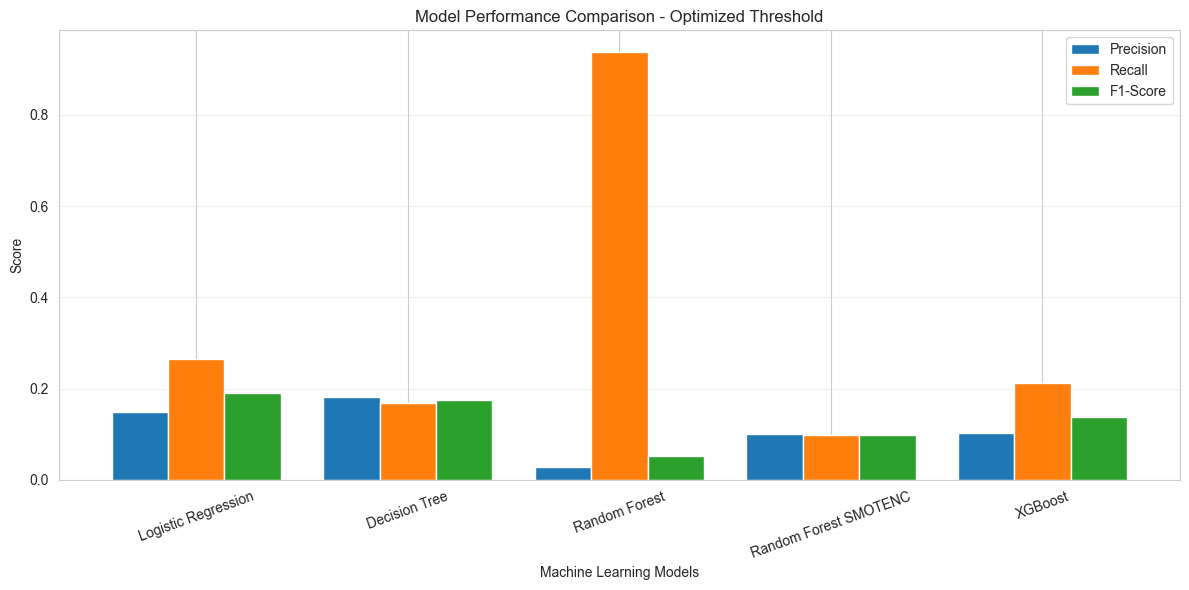

In [ ]:
# 8)  Model Evaluation Summary : 
metrics_to_plot = [
    "Precision",
    "Recall",
    "F1-Score"
]

plot_df = best_threshold_df.set_index("Model")[
    metrics_to_plot
]

ax = plot_df.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8
)

plt.title("Model Performance Comparison - Optimized Threshold")
plt.xlabel("Machine Learning Models")
plt.ylabel("Score")
plt.xticks(rotation=20)
plt.legend(loc="best")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(
    "reduced_model_performance.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

##### **Step 20 – Final Train-Validation-Test Split**

In [ ]:
# 1) Fresh Train, Validation, Test Split
from sklearn.model_selection import StratifiedGroupKFold

# Grouping using original 12 candidate features
fresh_groups = pd.util.hash_pandas_object(
    X_candidate,
    index=False
)

# First split: 80% Train + Validation, 20% Test
split_1 = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_val_idx, final_test_idx = next(
    split_1.split(X_candidate, y, groups=fresh_groups)
)

X_train_val = X_candidate.iloc[train_val_idx].copy()
y_train_val = y.iloc[train_val_idx].copy()

X_test_final = X_candidate.iloc[final_test_idx].copy()
y_test_final = y.iloc[final_test_idx].copy()

groups_train_val = fresh_groups.iloc[train_val_idx]

# Second split: 75% Train, 25% Validation
split_2 = StratifiedGroupKFold(
    n_splits=4,
    shuffle=True,
    random_state=42
)

train_idx_final, val_idx_final = next(
    split_2.split(
        X_train_val,
        y_train_val,
        groups=groups_train_val
    )
)

X_train_final = X_train_val.iloc[train_idx_final].copy()
y_train_final = y_train_val.iloc[train_idx_final].copy()

X_val_final = X_train_val.iloc[val_idx_final].copy()
y_val_final = y_train_val.iloc[val_idx_final].copy()

# Remove leakage-prone features
X_train_final.drop(columns=features_to_remove, inplace=True)
X_val_final.drop(columns=features_to_remove, inplace=True)
X_test_final.drop(columns=features_to_remove, inplace=True)

print("FINAL DATASET SPLIT")
print("-" * 40)

print("Training Shape:", X_train_final.shape)
print("Validation Shape:", X_val_final.shape)
print("Testing Shape:", X_test_final.shape)

print("\nTraining Class Distribution:")
print(y_train_final.value_counts())

print("\nValidation Class Distribution:")
print(y_val_final.value_counts())

print("\nTesting Class Distribution:")
print(y_test_final.value_counts())

FINAL DATASET SPLIT
----------------------------------------
Training Shape: (23360, 8)
Validation Shape: (7964, 8)
Testing Shape: (7897, 8)

Training Class Distribution:
label
0    23037
1      323
Name: count, dtype: int64

Validation Class Distribution:
label
0    7840
1     124
Name: count, dtype: int64

Testing Class Distribution:
label
0    7784
1     113
Name: count, dtype: int64


##### **Step 21 – Final Model Training & Evaluation**

In [ ]:
# 1) Final Training Data Preprocessing : 

# Convert categorical features to object
for col in categorical_features_reduced:

    X_train_final[col] = X_train_final[col].astype("object")
    X_val_final[col] = X_val_final[col].astype("object")
    X_test_final[col] = X_test_final[col].astype("object")


# Handle missing categorical values
X_train_final[categorical_features_reduced] = (
    X_train_final[categorical_features_reduced]
    .fillna("Unknown")
)

X_val_final[categorical_features_reduced] = (
    X_val_final[categorical_features_reduced]
    .fillna("Unknown")
)

X_test_final[categorical_features_reduced] = (
    X_test_final[categorical_features_reduced]
    .fillna("Unknown")
)


# Check missing values
print("Training Missing Values:",
      X_train_final.isnull().sum().sum())

print("Validation Missing Values:",
      X_val_final.isnull().sum().sum())

print("Testing Missing Values:",
      X_test_final.isnull().sum().sum())


print("\nFinal Preprocessing Data Shapes:")
print("Training:", X_train_final.shape)
print("Validation:", X_val_final.shape)
print("Testing:", X_test_final.shape)

Training Missing Values: 0
Validation Missing Values: 0
Testing Missing Values: 0

Final Preprocessing Data Shapes:
Training: (23360, 8)
Validation: (7964, 8)
Testing: (7897, 8)


In [ ]:
# 2) Final Training Data SMOTENC

from imblearn.over_sampling import SMOTENC
from sklearn.impute import SimpleImputer

# Copy final training data
X_train_smote_final = X_train_final.copy()

# Numerical imputation - fit only on training data
smote_imputer_final = SimpleImputer(strategy="median")

X_train_smote_final[numeric_features_reduced] = (
    smote_imputer_final.fit_transform(
        X_train_smote_final[numeric_features_reduced]
    )
)

# Identify categorical feature positions
categorical_indices_final = [
    X_train_smote_final.columns.get_loc(col)
    for col in categorical_features_reduced
]

# Apply SMOTENC
smotenc_final = SMOTENC(
    categorical_features=categorical_indices_final,
    sampling_strategy=0.5,
    random_state=42,
    k_neighbors=5
)

X_train_resampled_final, y_train_resampled_final = (
    smotenc_final.fit_resample(
        X_train_smote_final,
        y_train_final
    )
)

print("Original Training Shape:", X_train_final.shape)

print("Resampled Training Shape:",
      X_train_resampled_final.shape)

print("\nFinal Resampled Class Distribution:")
print(y_train_resampled_final.value_counts())

Original Training Shape: (23360, 8)
Resampled Training Shape: (34555, 8)

Final Resampled Class Distribution:
label
0    23037
1    11518
Name: count, dtype: int64


In [ ]:
# 3) Final Preprocessing Pipeline : 

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Numerical preprocessing
numeric_transformer_final = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer_final = Pipeline([
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value="Unknown"
    )),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combined preprocessing
preprocessor_final = ColumnTransformer([
    ("num", numeric_transformer_final, numeric_features_reduced),
    ("cat", categorical_transformer_final, categorical_features_reduced)
])

print("Final Preprocessing Pipeline Created Successfully!")
print("Numerical Features:", len(numeric_features_reduced))
print("Categorical Features:", len(categorical_features_reduced))

Final Preprocessing Pipeline Created Successfully!
Numerical Features: 5
Categorical Features: 3


In [ ]:
# 4) Create Final 5 Model Pipelines

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# 1. Logistic Regression
logistic_model_final = Pipeline([
    ("preprocessor", clone(preprocessor_final)),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    ))
])

# 2. Decision Tree
decision_tree_model_final = Pipeline([
    ("preprocessor", clone(preprocessor_final)),
    ("classifier", DecisionTreeClassifier(
        class_weight="balanced",
        max_depth=8,
        min_samples_split=10,
        min_samples_leaf=5,
        random_state=42
    ))
])

# 3. Random Forest
random_forest_model_final = Pipeline([
    ("preprocessor", clone(preprocessor_final)),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=12,
        min_samples_split=10,
        min_samples_leaf=3,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

# 4. Random Forest SMOTENC
random_forest_smote_model_final = Pipeline([
    ("preprocessor", clone(preprocessor_final)),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=12,
        min_samples_split=10,
        min_samples_leaf=3,
        random_state=42,
        n_jobs=-1
    ))
])

# 5. XGBoost
scale_pos_weight_final = (
    (y_train_final == 0).sum() /
    (y_train_final == 1).sum()
)

xgboost_model_final = Pipeline([
    ("preprocessor", clone(preprocessor_final)),
    ("classifier", XGBClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=5,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=scale_pos_weight_final,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ))
])

print("All 5 Final Models Created Successfully!")

All 5 Final Models Created Successfully!


In [ ]:
# 5) Train All 5 Models

# 1. Logistic Regression
logistic_model_final.fit(X_train_final, y_train_final)

# 2. Decision Tree
decision_tree_model_final.fit(X_train_final, y_train_final)

# 3. Random Forest
random_forest_model_final.fit(X_train_final, y_train_final)

# 4. Random Forest with SMOTENC
random_forest_smote_model_final.fit(
    X_train_resampled_final,
    y_train_resampled_final
)

# 5. XGBoost
xgboost_model_final.fit(X_train_final, y_train_final)

print("All 5 Final Models Trained Successfully!")

All 5 Final Models Trained Successfully!


In [ ]:
# 6) Validation Probability Predictions

logistic_val_proba = logistic_model_final.predict_proba(
    X_val_final
)[:, 1]

decision_tree_val_proba = decision_tree_model_final.predict_proba(
    X_val_final
)[:, 1]

random_forest_val_proba = random_forest_model_final.predict_proba(
    X_val_final
)[:, 1]

random_forest_smote_val_proba = (
    random_forest_smote_model_final.predict_proba(
        X_val_final
    )[:, 1]
)

xgboost_val_proba = xgboost_model_final.predict_proba(
    X_val_final
)[:, 1]

print("All 5 Models Validation Predictions Completed!")

print("\nValidation Probability Shapes:")
print("Logistic Regression:", logistic_val_proba.shape)
print("Decision Tree:", decision_tree_val_proba.shape)
print("Random Forest:", random_forest_val_proba.shape)
print("Random Forest SMOTENC:", random_forest_smote_val_proba.shape)
print("XGBoost:", xgboost_val_proba.shape)

All 5 Models Validation Predictions Completed!

Validation Probability Shapes:
Logistic Regression: (7964,)
Decision Tree: (7964,)
Random Forest: (7964,)
Random Forest SMOTENC: (7964,)
XGBoost: (7964,)


In [ ]:
# 7) Validation Threshold Optimization

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

validation_probabilities = {
    "Logistic Regression": logistic_val_proba,
    "Decision Tree": decision_tree_val_proba,
    "Random Forest": random_forest_val_proba,
    "Random Forest SMOTENC": random_forest_smote_val_proba,
    "XGBoost": xgboost_val_proba
}

threshold_results = []

threshold_values = np.arange(0.01, 1.00, 0.01)

for model_name, probabilities in validation_probabilities.items():

    best_threshold = 0
    best_f1 = 0
    best_precision = 0
    best_recall = 0

    for threshold in threshold_values:

        predictions = (probabilities >= threshold).astype(int)

        precision = precision_score(
            y_val_final, predictions, zero_division=0
        )

        recall = recall_score(
            y_val_final, predictions, zero_division=0
        )

        f1 = f1_score(
            y_val_final, predictions, zero_division=0
        )

        if f1 > best_f1:
            best_f1 = f1
            best_threshold = threshold
            best_precision = precision
            best_recall = recall

    threshold_results.append({
        "Model": model_name,
        "Best Threshold": best_threshold,
        "Precision": best_precision,
        "Recall": best_recall,
        "F1 Score": best_f1
    })

validation_threshold_df = pd.DataFrame(threshold_results)

validation_threshold_df = validation_threshold_df.sort_values(
    by="F1 Score", ascending=False
).reset_index(drop=True)

display(validation_threshold_df.round(4))


,Model,Best Threshold,Precision,Recall,F1 Score
0,Logistic Regression,0.88,0.1319,0.1532,0.1418
1,Decision Tree,0.95,0.2424,0.0645,0.1019
2,XGBoost,0.86,0.0826,0.0806,0.0816
3,Random Forest SMOTENC,0.78,0.1250,0.0565,0.0778
4,Random Forest,0.09,0.0316,0.9597,0.0612


In [ ]:
# 8) Final Test Evaluation : 
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

best_thresholds = dict(zip(
    validation_threshold_df["Model"],
    validation_threshold_df["Best Threshold"]
))

final_models = {
    "Logistic Regression": logistic_model_final,
    "Decision Tree": decision_tree_model_final,
    "Random Forest": random_forest_model_final,
    "Random Forest SMOTENC": random_forest_smote_model_final,
    "XGBoost": xgboost_model_final
}

final_test_results = []

final_test_predictions = {}

for model_name, model in final_models.items():

    probabilities = model.predict_proba(X_test_final)[:, 1]

    threshold = best_thresholds[model_name]

    predictions = (probabilities >= threshold).astype(int)

    final_test_predictions[model_name] = predictions

    final_test_results.append({
        "Model": model_name,
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test_final, predictions),
        "Precision": precision_score(
            y_test_final, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test_final, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test_final, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test_final, probabilities),
        "PR-AUC": average_precision_score(
            y_test_final, probabilities
        )
    })

final_test_df = pd.DataFrame(final_test_results)

final_test_df = final_test_df.sort_values(
    by="F1 Score", ascending=False
).reset_index(drop=True)

display(final_test_df.round(4))

,Model,Threshold,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,Logistic Regression,0.88,0.9718,0.1429,0.1947,0.1648,0.8419,0.0992
1,XGBoost,0.86,0.9745,0.1000,0.0973,0.0987,0.7479,0.0498
2,Decision Tree,0.95,0.9819,0.1591,0.0619,0.0892,0.7351,0.0652
3,Random Forest SMOTENC,0.78,0.9808,0.1176,0.0531,0.0732,0.7541,0.0431
4,Random Forest,0.09,0.5430,0.0265,0.8673,0.0515,0.7289,0.0251


In [ ]:
# 9)  Metrics verify again
from sklearn.metrics import confusion_matrix

for model_name, model in final_models.items():

    predictions = final_test_predictions[model_name]

    probabilities = model.predict_proba(X_test_final)[:, 1]

    print("\n", "=" * 55)
    print("MODEL:", model_name)
    print("=" * 55)

    print("Threshold:", best_thresholds[model_name])

    print("\nConfusion Matrix:")
    print(confusion_matrix(y_test_final, predictions))

    print("\nAccuracy:",
          accuracy_score(y_test_final, predictions))

    print("Precision:",
          precision_score(y_test_final, predictions, zero_division=0))

    print("Recall:",
          recall_score(y_test_final, predictions, zero_division=0))

    print("F1 Score:",
          f1_score(y_test_final, predictions, zero_division=0))

    print("ROC-AUC:",
          roc_auc_score(y_test_final, probabilities))

    print("PR-AUC:",
          average_precision_score(y_test_final, probabilities))


MODEL: Logistic Regression
Threshold: 0.88

Confusion Matrix:
[[7652  132]
 [  91   22]]

Accuracy: 0.971761428390528
Precision: 0.14285714285714285
Recall: 0.19469026548672566
F1 Score: 0.1647940074906367
ROC-AUC: 0.841884646517931
PR-AUC: 0.09915769349506516

MODEL: Decision Tree
Threshold: 0.9500000000000001

Confusion Matrix:
[[7747   37]
 [ 106    7]]

Accuracy: 0.9818918576674687
Precision: 0.1590909090909091
Recall: 0.061946902654867256
F1 Score: 0.08917197452229299
ROC-AUC: 0.735053297437903
PR-AUC: 0.06516130818856895

MODEL: Random Forest
Threshold: 0.09

Confusion Matrix:
[[4190 3594]
 [  15   98]]

Accuracy: 0.5429910092440167
Precision: 0.026543878656554713
Recall: 0.8672566371681416
F1 Score: 0.05151116951379763
ROC-AUC: 0.7288680433655604
PR-AUC: 0.02509027202588783

MODEL: Random Forest SMOTENC
Threshold: 0.78

Confusion Matrix:
[[7739   45]
 [ 107    6]]

Accuracy: 0.9807521843738128
Precision: 0.11764705882352941
Recall: 0.05309734513274336
F1 Score: 0.07317073170731

In [ ]:
# 10 ) Complete Final Results Table

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

print(final_test_df.to_string(index=False))

                Model  Threshold  Accuracy  Precision   Recall  F1 Score  ROC-AUC   PR-AUC
  Logistic Regression       0.88  0.971761   0.142857 0.194690  0.164794 0.841885 0.099158
              XGBoost       0.86  0.974547   0.100000 0.097345  0.098655 0.747922 0.049753
        Decision Tree       0.95  0.981892   0.159091 0.061947  0.089172 0.735053 0.065161
Random Forest SMOTENC       0.78  0.980752   0.117647 0.053097  0.073171 0.754096 0.043055
        Random Forest       0.09  0.542991   0.026544 0.867257  0.051511 0.728868 0.025090


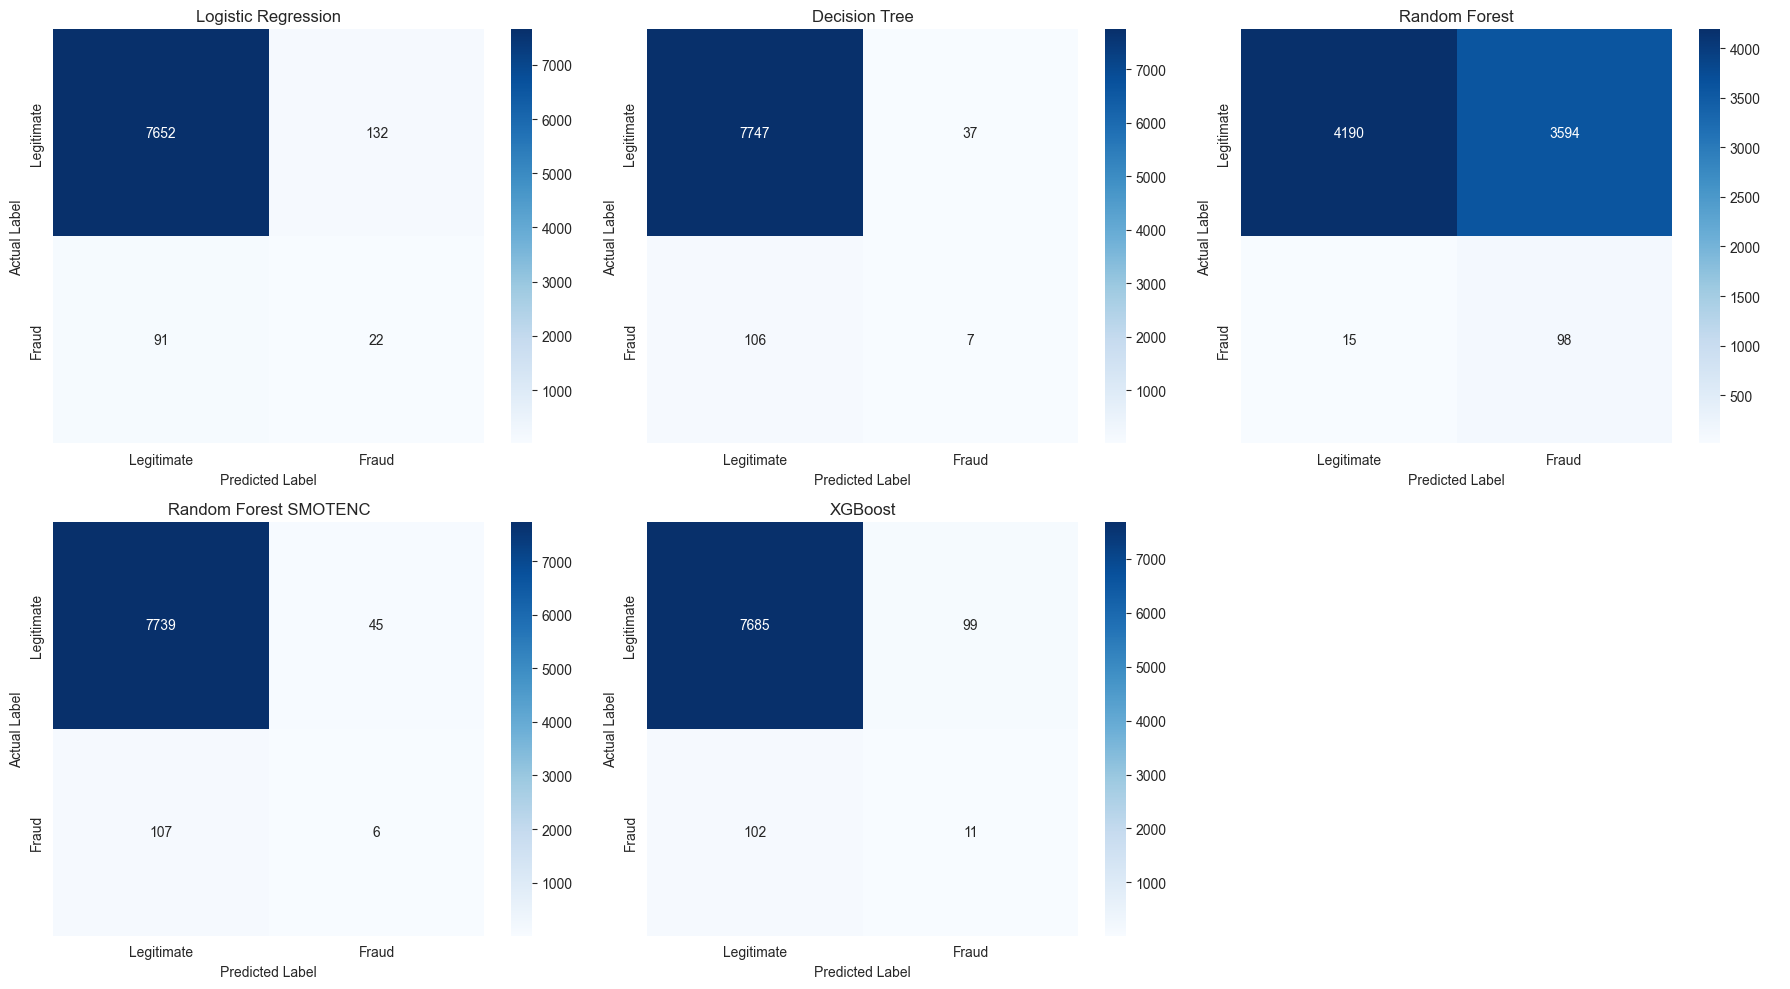

In [ ]:
# 11) Confusion Matrix Visualization

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, (model_name, predictions) in enumerate(
    final_test_predictions.items()
):
    cm = confusion_matrix(y_test_final, predictions)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Legitimate", "Fraud"],
        yticklabels=["Legitimate", "Fraud"],
        ax=axes[i]
    )

    axes[i].set_title(model_name)
    axes[i].set_xlabel("Predicted Label")
    axes[i].set_ylabel("Actual Label")

axes[5].axis("off")

plt.tight_layout()
plt.savefig(
    "final_confusion_matrices.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

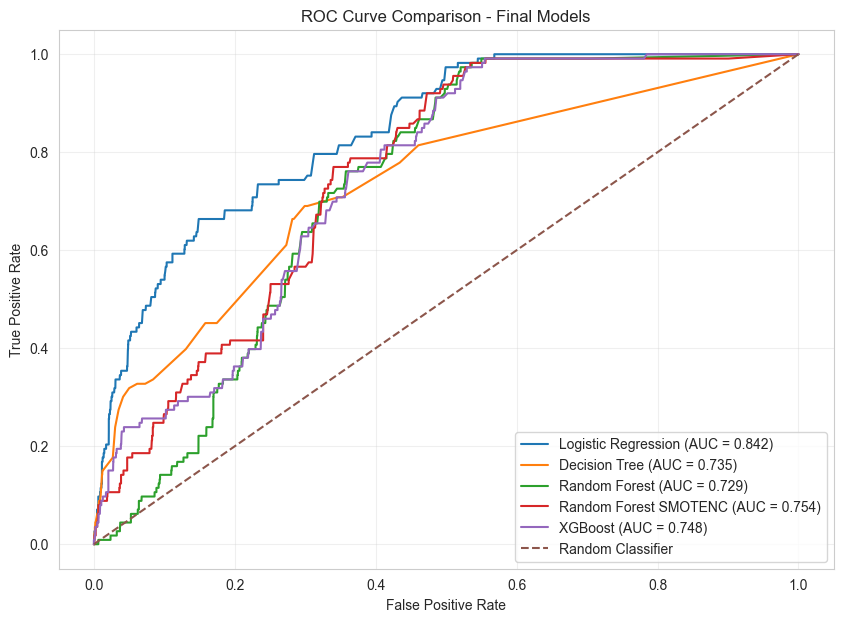

In [ ]:
# 12) ROC Curve Comparison

from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))

for model_name, model in final_models.items():

    probabilities = model.predict_proba(X_test_final)[:, 1]

    fpr, tpr, thresholds = roc_curve(
        y_test_final,
        probabilities
    )

    auc_score = roc_auc_score(
        y_test_final,
        probabilities
    )

    plt.plot(
        fpr,
        tpr,
        label=f"{model_name} (AUC = {auc_score:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison - Final Models")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)

plt.savefig(
    "final_roc_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

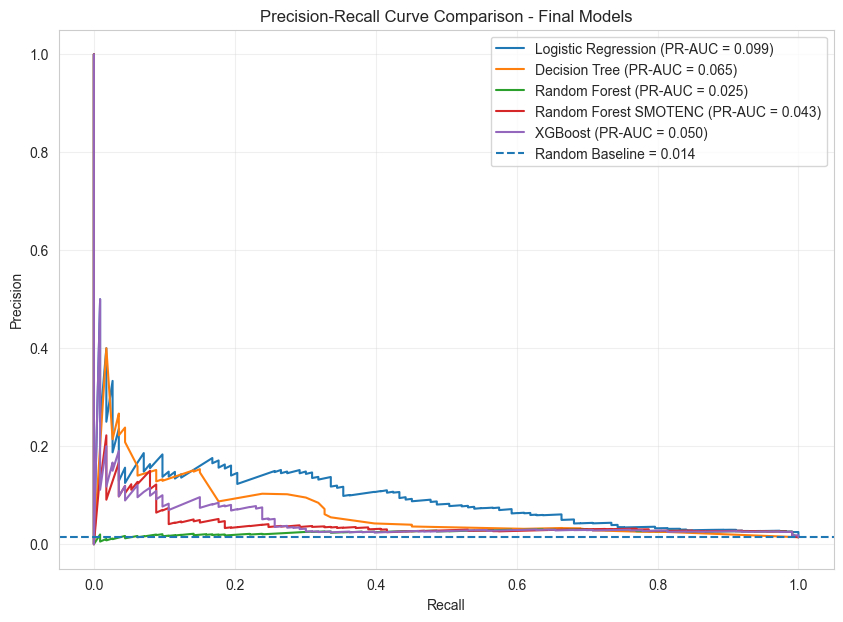

In [ ]:
# 13)  Precision-Recall Curve Comparison

from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score
)
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))

for model_name, model in final_models.items():

    probabilities = model.predict_proba(X_test_final)[:, 1]

    precision, recall, thresholds = precision_recall_curve(
        y_test_final,
        probabilities
    )

    pr_auc = average_precision_score(
        y_test_final,
        probabilities
    )

    plt.plot(
        recall,
        precision,
        label=f"{model_name} (PR-AUC = {pr_auc:.3f})"
    )

baseline = y_test_final.mean()

plt.axhline(
    y=baseline,
    linestyle="--",
    label=f"Random Baseline = {baseline:.3f}"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve Comparison - Final Models")
plt.legend(loc="upper right")
plt.grid(alpha=0.3)

plt.savefig(
    "final_precision_recall_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
# 14)  Logistic Regression Feature Importance
# Extract trained Logistic Regression classifier

logistic_classifier = (
    logistic_model_final.named_steps["classifier"]
)

# Get transformed feature names

feature_names = (
    logistic_model_final
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

# Extract coefficients

coefficients = logistic_classifier.coef_[0]

# Create feature importance dataframe

feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients,
    "Absolute Importance": np.abs(coefficients)
})

# Sort by absolute importance

feature_importance_df = feature_importance_df.sort_values(
    by="Absolute Importance",
    ascending=False
).reset_index(drop=True)

display(feature_importance_df.head(15).round(4))

,Feature,Coefficient,Absolute Importance
0,num__payment_age_log,-10.1137,10.1137
1,cat__item_group_Multiple,-1.6789,1.6789
2,cat__Category_unknown,1.3558,1.3558
3,cat__Category_shopping,-1.0823,1.0823
4,cat__Category_electronics,-0.9758,0.9758
5,cat__Category_food,-0.8989,0.8989
6,cat__paymentMethod_storecredit,-0.6937,0.6937
7,cat__item_group_Few,0.6370,0.6370
8,cat__item_group_Single,-0.5592,0.5592
9,cat__paymentMethod_paypal,-0.4650,0.4650


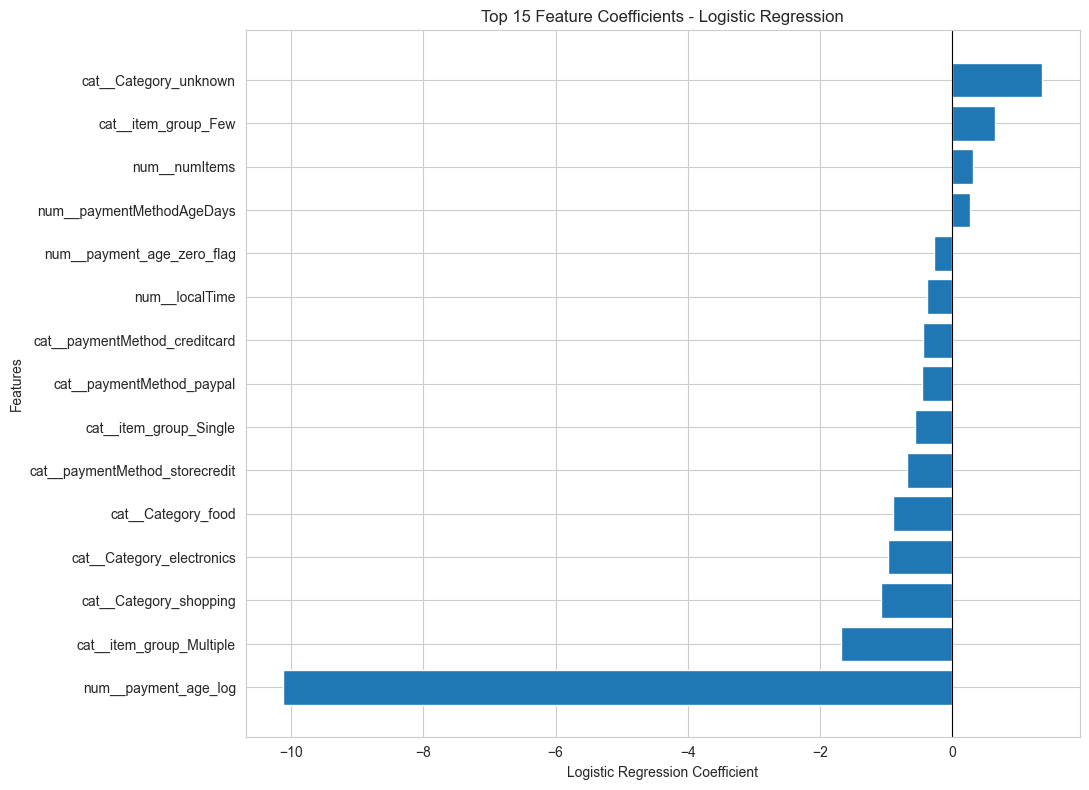

In [ ]:
# 15)  Feature Importance Visualization

# Logistic Regression Feature Importance Visualization
top_features = feature_importance_df.head(15).sort_values(
    by="Coefficient"
)

plt.figure(figsize=(11, 8))

plt.barh(
    top_features["Feature"],
    top_features["Coefficient"]
)

plt.axvline(x=0, color="black", linewidth=0.8)

plt.xlabel("Logistic Regression Coefficient")
plt.ylabel("Features")
plt.title("Top 15 Feature Coefficients - Logistic Regression")

plt.tight_layout()

plt.savefig(
    "logistic_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

##### **Step 22 – Best Model Selection & Model Saving**

In [137]:
import joblib
import os

# Create model directory
os.makedirs("saved_models", exist_ok=True)

# Save complete model pipeline
joblib.dump(
    logistic_model_final,
    "saved_models/fraud_detection_model.pkl"
)

# Save selected threshold
joblib.dump(
    best_thresholds["Logistic Regression"],
    "saved_models/fraud_threshold.pkl"
)

print("Best Model Saved Successfully!")
print("Model: Logistic Regression")
print("Threshold:", best_thresholds["Logistic Regression"])
print("Model Path: saved_models/fraud_detection_model.pkl")

Best Model Saved Successfully!
Model: Logistic Regression
Threshold: 0.88
Model Path: saved_models/fraud_detection_model.pkl


##### **Step No 23 – Saved Model Loading & Testing**

In [138]:
import joblib
import numpy as np

# Load saved model
loaded_model = joblib.load(
    "saved_models/fraud_detection_model.pkl"
)

# Load saved threshold
loaded_threshold = joblib.load(
    "saved_models/fraud_threshold.pkl"
)

# Test prediction using final test data
test_probabilities = loaded_model.predict_proba(
    X_test_final
)[:, 1]

test_predictions = (
    test_probabilities >= loaded_threshold
).astype(int)

print("Saved Model Loaded Successfully!")

print("Loaded Threshold:", loaded_threshold)

print("\nFirst 10 Fraud Probabilities:")
print(test_probabilities[:10])

print("\nFirst 10 Predictions:")
print(test_predictions[:10])

print("\nPrediction Completed Successfully!")

Saved Model Loaded Successfully!
Loaded Threshold: 0.88

First 10 Fraud Probabilities:
[5.04159530e-01 5.36719822e-01 9.32326375e-03 2.50016932e-05
 4.68356010e-01 4.55165265e-01 5.50188141e-01 7.15403478e-01
 5.98428030e-01 6.12435115e-01]

First 10 Predictions:
[0 0 0 0 0 0 0 0 0 0]

Prediction Completed Successfully!


##### **Step 24 – Streamlit Application Development**

In [139]:
print("Required Input Features:")
print(X_train_final.columns.tolist())

Required Input Features:
['numItems', 'localTime', 'paymentMethodAgeDays', 'payment_age_log', 'payment_age_zero_flag', 'paymentMethod', 'Category', 'item_group']


##### **Create app.py**

In [141]:

import streamlit as st
import pandas as pd
import numpy as np
import joblib
import os

# ------------------------------------------------
# 1. PAGE CONFIGURATION
# ------------------------------------------------

st.set_page_config(
    page_title="Machine Learning Fraud Detection",
    page_icon="",
    layout="wide"
)

st.title(" Machine Learning-Based Financial Fraud Detection")
st.write(
    "A Machine Learning System for Financial Transaction "
    "Fraud Detection and Risk Analysis"
)

st.divider()

# ------------------------------------------------
# 2. LOAD SAVED MODEL
# ------------------------------------------------

MODEL_PATH = "saved_models/fraud_detection_model.pkl"
THRESHOLD_PATH = "saved_models/fraud_threshold.pkl"


@st.cache_resource
def load_model():

    model = joblib.load(MODEL_PATH)
    threshold = joblib.load(THRESHOLD_PATH)

    return model, threshold


if not os.path.exists(MODEL_PATH):
    st.error("Fraud detection model file not found!")
    st.stop()

if not os.path.exists(THRESHOLD_PATH):
    st.error("Threshold file not found!")
    st.stop()

model, threshold = load_model()

# ------------------------------------------------
# 3. MODEL INFORMATION
# ------------------------------------------------

st.subheader("Model Information")

col1, col2, col3 = st.columns(3)

col1.metric("ML Algorithm", "Logistic Regression")
col2.metric("Classification Threshold", f"{threshold:.2f}")
col3.metric("Model Status", "Loaded Successfully")

st.divider()

# ------------------------------------------------
# 4. USER INPUT
# ------------------------------------------------

st.subheader("Enter Financial Transaction Details")

col1, col2 = st.columns(2)

with col1:

    numItems = st.number_input(
        "Number of Items",
        min_value=1,
        value=1,
        step=1
    )

    localTime = st.number_input(
        "Local Time",
        value=0.0
    )

    paymentMethodAgeDays = st.number_input(
        "Payment Method Age (Days)",
        min_value=0.0,
        value=1.0
    )

with col2:

    paymentMethod = st.text_input(
        "Payment Method",
        placeholder="Example: creditcard"
    )

    Category = st.text_input(
        "Transaction Category",
        placeholder="Example: electronics"
    )

st.divider()

# ------------------------------------------------
# 5. FEATURE ENGINEERING
# ------------------------------------------------

if st.button("Analyze Transaction", type="primary"):

    if not paymentMethod.strip() or not Category.strip():

        st.warning(
            "Please enter Payment Method and Category."
        )

        st.stop()

    if not np.isfinite(localTime) or not np.isfinite(paymentMethodAgeDays):
        st.error("Please enter valid numerical values.")
        st.stop()

    # Normalize categorical values

    payment_method_clean = paymentMethod.strip().lower()
    category_clean = Category.strip().lower()

    # Log transformation

    payment_age_log = np.log1p(
        paymentMethodAgeDays
    )

    # Zero flag

    payment_age_zero_flag = int(
        paymentMethodAgeDays == 0
    )

    # Item group generation

    if numItems <= 1:

        item_group = "Single"

    elif numItems <= 5:

        item_group = "Few"

    else:

        item_group = "Multiple"

    # Create transaction dataframe

    input_data = pd.DataFrame([{

        "numItems": numItems,

        "localTime": localTime,

        "paymentMethodAgeDays": paymentMethodAgeDays,

        "payment_age_log": payment_age_log,

        "payment_age_zero_flag": payment_age_zero_flag,

        "paymentMethod": payment_method_clean,

        "Category": category_clean,

        "item_group": item_group

    }])

    # ------------------------------------------------
    # 6. FRAUD PREDICTION
    # ------------------------------------------------

    fraud_probability = model.predict_proba(
        input_data
    )[0][1]

    prediction = int(
        fraud_probability >= threshold
    )

    # ------------------------------------------------
    # 7. DISPLAY TRANSACTION DETAILS
    # ------------------------------------------------

    st.subheader("Transaction Summary")

    st.dataframe(
        input_data,
        use_container_width=True
    )

    # ------------------------------------------------
    # 8. DISPLAY PREDICTION RESULTS
    # ------------------------------------------------

    st.subheader("Fraud Detection Results")

    col1, col2 = st.columns(2)

    with col1:

        st.metric(
            "Fraud Probability",
            f"{fraud_probability * 100:.2f}%"
        )

    with col2:

        st.metric(
            "Classification Threshold",
            f"{threshold * 100:.0f}%"
        )

    st.progress(float(fraud_probability))

    # ------------------------------------------------
    # 9. RISK CLASSIFICATION
    # ------------------------------------------------

    if prediction == 1:

        st.error(
            " FRAUDULENT TRANSACTION DETECTED"
        )

        st.write(
            "The transaction has been classified as Fraud "
            "by the Machine Learning model."
        )

        st.warning(
            "Further manual verification is recommended."
        )

    else:

        st.success(
            " LEGITIMATE CLASSIFICATION"
        )

        st.write(
            "The transaction is below the configured "
            "fraud classification threshold."
        )

    st.divider()

    st.caption(
        "This application uses a trained Logistic Regression "
        "Machine Learning model. Predictions are experimental "
        "and should not be treated as confirmed fraud decisions."
    )

# ------------------------------------------------
# 10. FOOTER
# ------------------------------------------------

st.divider()

st.caption(
    "Financial Fraud Detection Using Machine Learning | "
    "Logistic Regression | Python | Scikit-learn | Streamlit"
)


2026-11-09 23:56:55.558 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-09 23:56:55.560 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-09 23:56:55.560 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-09 23:56:55.561 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-09 23:56:55.562 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-09 23:56:55.563 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-09 23:56:55.564 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-09 23:56:55.564 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bar

DeltaGenerator()

##### **Step No 25 - Final Project Summary & Conclusion**

## 1. Final Project Summary

The **Financial Fraud Detection Using Machine Learning** project aims to identify potentially fraudulent financial transactions using machine learning classification techniques.

The project uses a financial transaction dataset containing **39,221 records and 8 original features**. The target variable is `label`, where:

- `0` – Legitimate Transaction
- `1` – Potentially Fraudulent Transaction

The project follows a structured end-to-end Data Science and Machine Learning workflow.

### Project Implementation Workflow

1. Importing Required Libraries
2. Dataset Loading
3. Data Understanding
4. Data Validation
5. Data Cleaning
6. Exploratory Data Analysis (EDA)
   - Univariate Analysis
   - Bivariate Analysis
   - Multivariate Analysis
   - Statistical Analysis
7. Target Variable Analysis
8. Feature Engineering
9. Feature Selection
10. Train-Test Split and Data Leakage Verification
11. Data Processing
12. Imbalanced Data Handling
13. SMOTENC Oversampling
14. Baseline Model Development
15. Machine Learning Model Building
16. Model Performance Evaluation
17. Fraud Pattern and Feature Analysis
18. Feature Leakage Investigation and Feature Reduction
19. Reduced Model Comparison and Threshold Analysis
20. Final Train-Validation-Test Split
21. Final Model Training and Evaluation
22. Model Saving
23. Saved Model Loading and Testing
24. Streamlit Application Development

## 2. Machine Learning Algorithms Implemented

The following classification algorithms were implemented and evaluated:

1. Logistic Regression
2. Decision Tree Classifier
3. Random Forest Classifier
4. Random Forest with SMOTENC
5. XGBoost Classifier

A Baseline Model was also developed to establish a reference for model performance.

## 3. Data Preprocessing and Feature Engineering

The project includes the following data preparation techniques:

- Missing value handling.
- Categorical data standardization.
- Numerical feature preprocessing.
- Median imputation.
- Standard Scaling.
- One-Hot Encoding.
- Log Transformation.
- Account and payment-method age-based feature engineering.
- Item grouping.
- Feature selection and feature reduction.
- Feature leakage investigation.
- Class imbalance handling using SMOTENC.

## 4. Model Evaluation Techniques

The models were evaluated using the following classification metrics:

- Accuracy
- Precision
- Recall
- F1-Score
- ROC-AUC
- PR-AUC
- Confusion Matrix

Additional evaluation techniques included:

- Classification threshold analysis.
- ROC Curve comparison.
- Precision-Recall Curve comparison.
- Feature coefficient analysis.

## 5. Final Model Development

The final model development process includes:

- Final Train-Validation-Test splitting.
- Training five classification models.
- Validation probability predictions.
- Decision threshold optimization using validation data.
- Final test performance evaluation.
- Confusion Matrix visualization.
- ROC Curve and Precision-Recall Curve analysis.
- Feature coefficient analysis.
- Model saving and loading.
- Prediction testing.

The final model and its classification threshold are saved using Joblib for further application integration.

## 6. Streamlit Application Development

A Streamlit-based application was developed to provide an interactive financial fraud detection interface.

The application allows users to:

- Enter financial transaction details.
- Submit transaction information for analysis.
- Generate fraud probability.
- Apply the saved classification threshold.
- Display the predicted transaction category.

The application demonstrates how a trained machine learning model can be integrated into an interactive prediction system.

## 7. Final Project Conclusion

This project demonstrates the practical application of Python, Data Analysis, and Machine Learning techniques in financial fraud detection.

Throughout the project, data validation, exploratory data analysis, statistical analysis, feature engineering, feature selection, and feature leakage investigation were performed to develop a structured and reliable machine learning workflow.

Five classification algorithms were implemented and evaluated using appropriate performance metrics, with particular attention to Precision, Recall, F1-Score, ROC-AUC, and PR-AUC due to the imbalanced nature of the dataset.

A final machine learning pipeline was developed using train-validation-test splitting and validation-based threshold optimization. The trained model was then saved and integrated into a Streamlit application for interactive fraud prediction.

Overall, this project provides practical experience in developing, evaluating, and deploying an end-to-end machine learning-based financial fraud detection prototype.

## 8. Project Limitations

- The dataset contains a highly imbalanced target distribution.
- Some data patterns require further investigation.
- The dataset does not provide a transaction ID.
- Independent real-world validation is required.
- Predictions should be reviewed by humans before operational decisions.

## 9. Future Scope

The project can be extended through the following improvements:

1. Collecting larger and more diverse financial transaction datasets.
2. Improving fraud detection performance.
3. Exploring cost-sensitive learning and alternative imbalance-handling techniques.
4. Performing additional feature engineering and model optimization.
5. Testing the model on new and unseen financial transactions.
6. Implementing real-time transaction monitoring.
7. Introducing human-review and alert mechanisms.
8. Improving application security and deployment infrastructure.

## 10. Final Outcome

An end-to-end **Machine Learning-Based Financial Fraud Detection Prototype** developed using Python, Pandas, NumPy, Scikit-learn, XGBoost, SMOTENC, Joblib, and Streamlit.

The project includes five evaluated classification models, a final prediction pipeline, and an interactive Streamlit fraud detection application.